# Gráficas capítulo introductorio: ρ vs a(t), a(t) vs t, Χ(z) vs z

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math
import scipy.constants as const
from astropy.cosmology import WMAP9 as cosmo
from astropy.cosmology import FlatLambdaCDM
import astropy.units as u
from astropy.cosmology import Planck18

## 1. ρ vs a(t)

a_eq rad–matter = 0.0002860767522993974
a_eq matter–Λ = 0.7722203003443452
a_eq rad–Λ = 0.1071338105959005


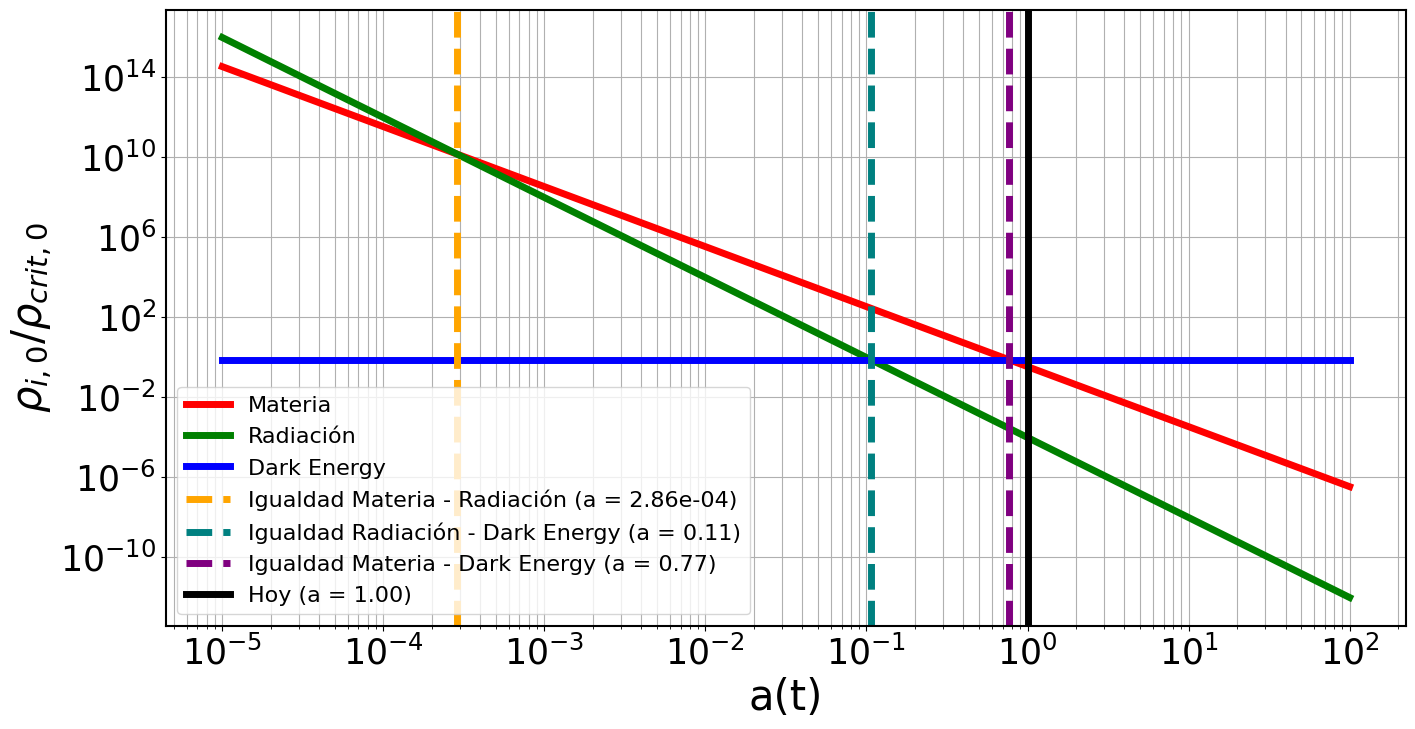

In [3]:
# Factor de escala solo positivo
a = np.logspace(-5, 2, 1000)  # desde a=10^-10 hasta 10000
a_0 = 1

#Datos Tabla 2.1 pg 58 Baumann:
Ω_m0 = 0.3153
Ω_r0 = 9.02e-5
Ω_Λ0 = 0.6847

# Funciones de densidad (normalizada, adimensional): 
ρ_matter = Ω_m0 * a**(-3)
ρ_rad = Ω_r0 * a**(-4)
ρ_Λ = Ω_Λ0 * a**0 # se podría usar: np.ones_like(a)

# Igualdad:
a_eq_rad_matter = Ω_r0 / Ω_m0        # ρ_rad = ρ_matter
a_eq_matter_Λ = (Ω_m0/Ω_Λ0)**(1/3)   # ρ_matter = ρ_Λ
a_eq_rad_Λ = (Ω_r0/Ω_Λ0)**(1/4)      # ρ_rad = ρ_Λ
a_present = 1

print("a_eq rad–matter =", a_eq_rad_matter)
print("a_eq matter–Λ =", a_eq_matter_Λ)
print("a_eq rad–Λ =", a_eq_rad_Λ)

# Tamaño gráfica
plt.figure(figsize = (16, 8))

# Graficar funciones
plt.loglog(a, ρ_matter, label = 'Materia', color='red', lw=5)
plt.loglog(a, ρ_rad, label = 'Radiación', color='green', lw=5)
plt.loglog(a, ρ_Λ, label = 'Dark Energy',color='blue', lw=5)

plt.axvline(a_eq_rad_matter, color='orange', linestyle='--', 
            label=f"Igualdad Materia - Radiación (a = {a_eq_rad_matter:.2e})", lw=5)
plt.axvline(a_eq_rad_Λ, color='teal', linestyle='--', 
            label=f"Igualdad Radiación - Dark Energy (a = {a_eq_rad_Λ:.2f})", lw=5)
plt.axvline(a_eq_matter_Λ, color='purple', linestyle='--', 
            label=f"Igualdad Materia - Dark Energy (a = {a_eq_matter_Λ:.2f})", lw=5)
plt.axvline(a_present, color='black', linestyle='-', 
            label=f"Hoy (a = {a_present:.2f})", lw=5)

# Título de la gráfica
#plt.title('Evolución de la densidad de materia, radiación y energía oscura con el factor de escala temporal', fontsize = 20, fontweight = 'bold', color = 'black')

# Títulos de ejes
plt.xlabel('a(t)', fontsize = 30, color = 'black')
plt.ylabel(r"$\rho_{i,0} / \rho_{crit,0}$", fontsize = 30, color = 'black')

# Etiquetas de los ejes
    # Tamaño
plt.xticks(fontsize = 25)
plt.yticks(fontsize = 25) 

# Trazar los ejes x=0 e y=0 en negrita
ax = plt.gca()
ax.axhline(0, color = 'black', linewidth = 1.0)
ax.axvline(0, color = 'black', linewidth = 1.0)
for spine in ax.spines.values():
    spine.set_linewidth(1.5)

# Leyenda
plt.legend(fontsize = 16)
#plt.legend(fontsize = 15, bbox_to_anchor = (1.05,1), loc = 'upper left')

# Guardar figura
plt.grid(True, which = 'both')
plt.savefig("Fig1_rho(a).png")

# Mostrar gráfica
plt.show()

### Cálculo ρ_crítica

In [3]:
# Cálculo ρ_crit:
h_name = ["Supernovae", "CMB"]
h = [0.730,0.674]

H_0 = np.zeros(2)
for i in range(2):
    H_0[i] = 100 * h[i]  / 3.086e+19  # Unidades: km s^-1 Mpc^-1 / 3.086e+19 = s^-1
    
G = 6.67 * 10**(-11) # Unidades: Nm^2/kg^2
ρ_crit = 3.0 / (8.0 * math.pi * G) * H_0**2

for i in range(2):
    print("\n",h_name[i],"\n H_0:",H_0[i],"\n ρ_crit:",ρ_crit[i])

print("\nNos quedamos con ρ_crit",h_name[1],"porque entra dentro de (8.62+-0.12)e-27:",ρ_crit[1]+0.12e-27)


 Supernovae 
 H_0: 2.3655217109526895e-18 
 ρ_crit: 1.0014042676939319e-26

 CMB 
 H_0: 2.184057031756319e-18 
 ρ_crit: 8.536572060629174e-27

Nos quedamos con ρ_crit CMB porque entra dentro de (8.62+-0.12)e-27: 8.656572060629174e-27


## 2. a(t) vs t

### Resolución para SOLO MATERIA

N_F: 2500
N_B: 1380
tB: [ 0.000e+00 -1.000e-02 -2.000e-02 ... -1.377e+01 -1.378e+01 -1.379e+01] 

H_0 en s^-1 = 2.184057031756319e-18
H_0 en Gy^-1 = 0.06887642255346728

ρ_crit: 2.677338798165868e+23


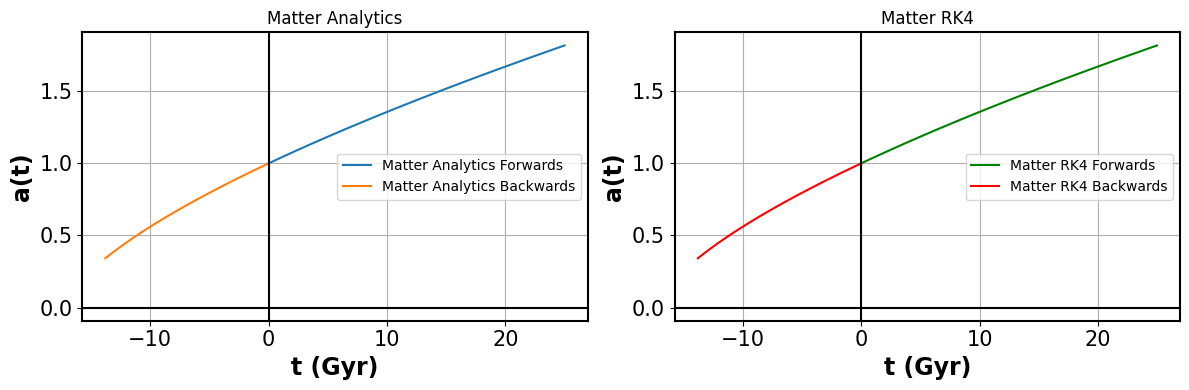

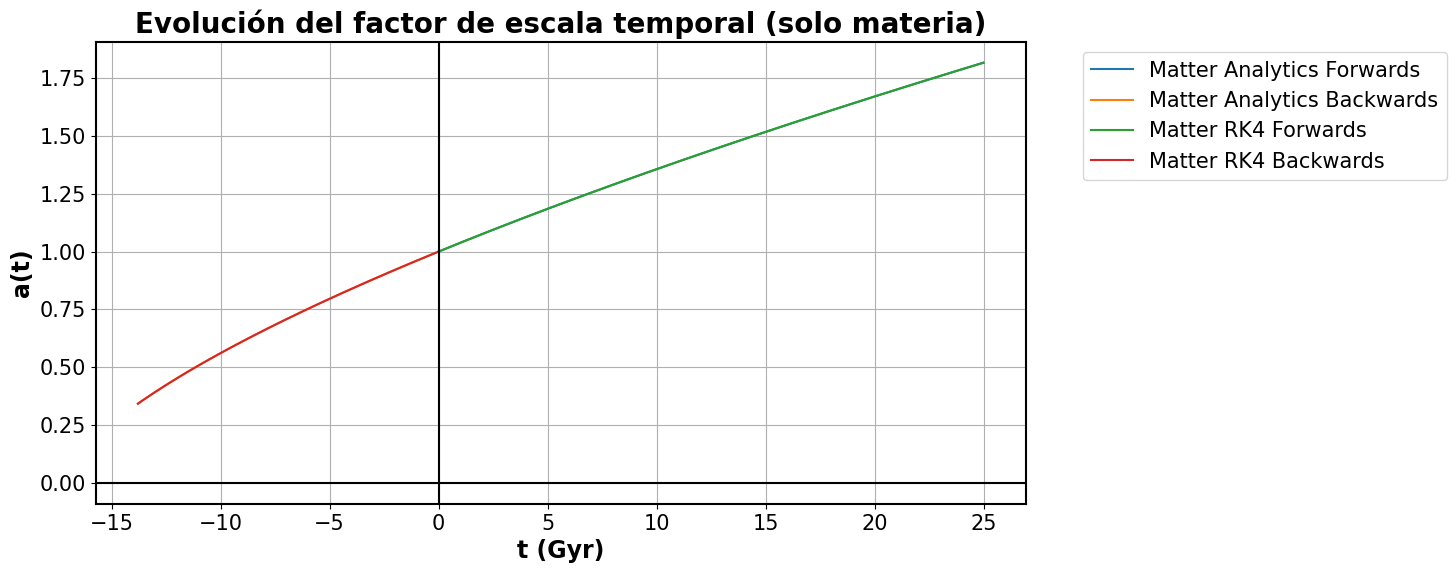

In [4]:
#......................................................
# Resolución para SOLO MATERIA: numérica vs analítica
#......................................................

#---------------------------
# Datos del eje x - temporal 
#---------------------------

t = 0.0  # hoy
dt = 0.01  # 0.01 Gyr = 10 Myr
tF_max = 25.0  # 25 Gyr en el futuro
tB_min = -13.8  # hasta casi el Big Bang
N_F = int((tF_max - t) / dt)
print("N_F:",N_F)
N_B = int((t - tB_min) / dt)
print("N_B:",N_B)

tF = np.arange(0.0, tF_max, dt)
tB = np.arange(0.0, tB_min, -dt)
print("tB:",tB,"\n")

#------------
# Constantes 
#------------

# Usamos pues H_0 del CMB, en Gyr:
H_0 = 67.4 / 3.086e+19 # Unidades: s^-1
print("H_0 en s^-1 =",H_0)
H_0 *= 3600 * 24 * 365 * 10**(9) # Unidades: Gyr^-1
print("H_0 en Gy^-1 =",H_0)
G = 6.67 * 10**(-11) # Unidades: N*m^2/kg^2
ρ_crit0 = 3.0 / (8.0 * math.pi * G) * H_0**2 # Unidades: kg^2/(N*m^2) * Gyr^-2
ρ_crit0 *= 3600 * 24 * 365 * 10**(9) # Unidades: kg/(m*Gyr)
print("\nρ_crit:",ρ_crit0)

# Datos Tabla 2.1 pg 58 Baumann:
Ω_m0 = 0.3153  
sqrtΩ_m0 = math.sqrt(Ω_m0)

#---------
# FUNCIÓN: a_punto[i] = H_0 * sqrtΩ[i] * a[i]**(-1/2*(1+3*ω[i]))
#---------

# Resolución ANALÍTICA ---------------
fF = (3/2 * H_0 * sqrtΩ_m0 * tF + 1)**(2/3)
fB = (3/2 * H_0 * sqrtΩ_m0 * tB + 1)**(2/3)
#-------------------------------------


#--------------------
# FUNCIÓN A RESOLVER: a_punto = H_0 * sqrtΩ[i] * a[i]**(-1/2*(1+3*ω[i]))
# PARA SOLO MATERIA: a_punto = H_0 * sqrtΩ[i] * a[i]**(-1/2)
#--------------------

#---------------------
# Resolución NUMÉRICA
#---------------------

# FORWARDS -----------
a_numF = np.zeros(N_F)
a_numF[0] = 1.0   # empezamos en 1
#a_numF[0] = 1e-6   # empezamos cerca de cero, no en 1    

for i in range(N_F-1):
    aF = a_numF[i]
    k1 = H_0 * sqrtΩ_m0 * aF**(-1/2)
    k2 = H_0 * sqrtΩ_m0 * (aF + 0.5 * dt * k1)**(-1/2)
    k3 = H_0 * sqrtΩ_m0 * (aF + 0.5 * dt * k2)**(-1/2)
    k4 = H_0 * sqrtΩ_m0 * (aF + dt * k3)**(-1/2)
    #print(f'{k1:.2e}', f'{k2:.2e}', f'{k3:.2e}', f'{k4:.2e}', a)
    a_numF[i+1] = aF + dt * (k1 + 2*k2 + 2*k3 + k4)/6
    
# BACKWARDS---------
a_numB = np.zeros(N_B)
a_numB[0] = 1.0   # empezamos en 1
#a_numB[0] = 1e-6   # empezamos cerca de cero, no en 1
dt=-dt
for i in range(N_B-1):
    aB = a_numB[i]
    k1 = H_0 * sqrtΩ_m0 * aB**(-1/2)
    k2 = H_0 * sqrtΩ_m0 * (aB + 0.5 * dt * k1)**(-1/2)
    k3 = H_0 * sqrtΩ_m0 * (aB + 0.5 * dt * k2)**(-1/2)
    k4 = H_0 * sqrtΩ_m0 * (aB + dt * k3)**(-1/2)
    #print(f'{k1:.2e}', f'{k2:.2e}', f'{k3:.2e}', f'{k4:.2e}', a)
    a_numB[i+1] = aB + dt * (k1 + 2*k2 + 2*k3 + k4)/6
    

#----------------------------------------
                # PLOT
#----------------------------------------


# GRÁFICAS PARALELAS Y SEPARADAS -------------------------------------------------------------------------------

fig, axs = plt.subplots(1, 2, figsize=(12, 4))

# ---- Gráfica Analítica ----
axs[0].plot(tF, fF, label="Matter Analytics Forwards")
axs[0].plot(tB, fB, label="Matter Analytics Backwards")
axs[0].set_title("Matter Analytics")
axs[0].legend()
axs[0].grid(True)

# ---- Gráfica Numérica ----
axs[1].plot(tF, a_numF, label="Matter RK4 Forwards", color='green')
axs[1].plot(tB, a_numB, label="Matter RK4 Backwards", color='red')
axs[1].set_title("Matter RK4")
axs[1].legend()
axs[1].grid(True)

# ---- Ajustes COMUNES a ambos subplots ----
for ax in axs:
    # Títulos de los ejes
    ax.set_xlabel('t (Gyr)', fontsize=17, fontweight='bold')
    ax.set_ylabel('a(t)', fontsize=17, fontweight='bold')

    # Etiquetas de los ticks
    ax.tick_params(axis='both', labelsize=15)

    # Ejes x=0 e y=0 en negrita
    ax.axhline(0, color='black', linewidth=1.5)
    ax.axvline(0, color='black', linewidth=1.5)

    # Ejes (spines) en negrita
    for spine in ax.spines.values():
        spine.set_linewidth(1.5)

plt.tight_layout()
plt.show()


# GRÁFICA INICIAL CON TODO JUNTO -------------------------------------------------------------------------------

# Tamaño --------------------------------
plt.figure(figsize = (12,6))
#plt.plot(t, a, label = "Matter")  
#plt.plot(t, a_num, label = "Matter RK4")

# Ploteo --------------------------------
plt.plot(tF, fF, label = "Matter Analytics Forwards")
plt.plot(tB, fB, label = "Matter Analytics Backwards")
plt.plot(tF, a_numF, label = "Matter RK4 Forwards") 
plt.plot(tB, a_numB, label = "Matter RK4 Backwards")

# Título y tamaño de gráfica ------------
plt.title('Evolución del factor de escala temporal (solo materia)', 
          fontsize = 20, fontweight = 'bold', color = 'black')

# Títulos de ejes------------------------
plt.xlabel('t (Gyr)', fontsize = 17, fontweight = 'bold', color = 'black')
plt.ylabel('a(t)', fontsize = 17, fontweight = 'bold', color = 'black')

# Etiquetas de los ejes -----------------
    # Tamaño
plt.xticks(fontsize = 15)
plt.yticks(fontsize = 15)

# Trazar los ejes x=0 e y=0 en negrita --
ax = plt.gca()
ax.axhline(0, color = 'black', linewidth = 1.5)
ax.axvline(0, color = 'black', linewidth = 1.5)
for spine in ax.spines.values():
    spine.set_linewidth(1.5)

# Leyenda--------------------------------
plt.legend(fontsize = 15, bbox_to_anchor = (1.05,1), loc = 'upper left')

# Mostrar gráfico -----------------------
plt.grid(True)
plt.show()

### Resolución para SOLO RADIACIÓN

N_F: 2500
N_B: 1380
tB: [ 0.000e+00 -1.000e-02 -2.000e-02 ... -1.377e+01 -1.378e+01 -1.379e+01] 

H_0 en s^-1 = 2.184057031756319e-18
H_0 en Gy^-1 = 0.06887642255346728

ρ_crit: 2.677338798165868e+23


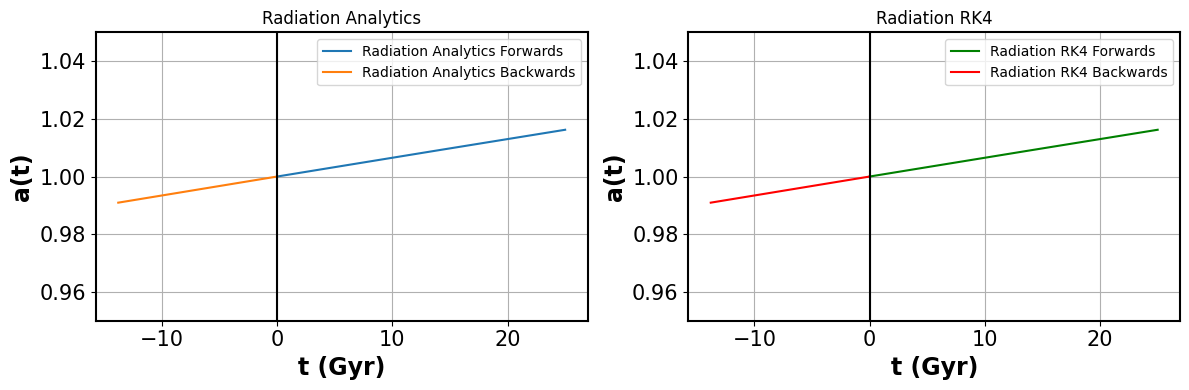

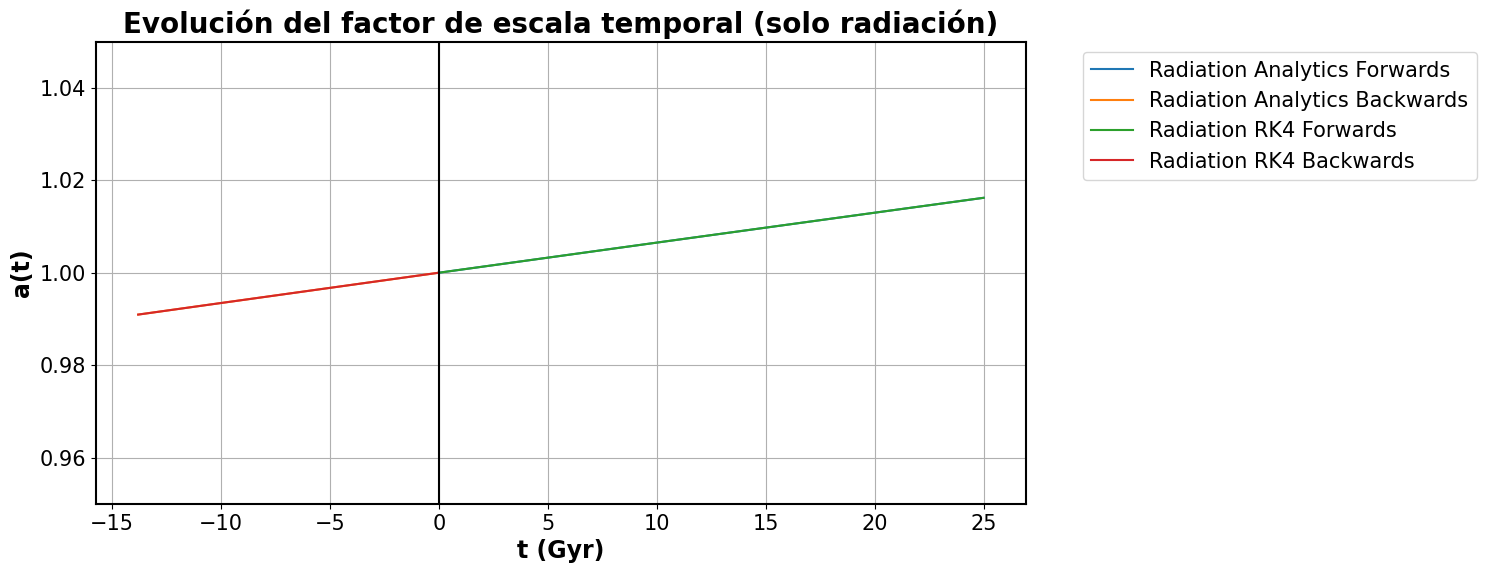

NOTA: Debido a que la constante que acompaña a t en esta resolución:  0.0013082894708060485 es tan cercana a 0, la gráfica queda prácticamente una recta


In [5]:
#......................................................
# Resolución para SOLO RADIACIÓN: numérica vs analítica
#......................................................

#---------------------------
# Datos del eje x - temporal 
#---------------------------

t = 0.0  # hoy
dt = 0.01  # 0.01 Gyr = 10 Myr
tF_max = 25.0  # 25 Gyr en el futuro
tB_min = -13.8  # hasta casi el Big Bang
N_F = int((tF_max - t) / dt)
print("N_F:",N_F)
N_B = int((t - tB_min) / dt)
print("N_B:",N_B)

tF = np.arange(0.0, tF_max, dt)
tB = np.arange(0.0, tB_min, -dt)
print("tB:",tB,"\n")

#------------
# Constantes 
#------------

# Usamos pues H_0 del CMB, en Gyr:
H_0 = 67.4 / 3.086e+19 # Unidades: s^-1
print("H_0 en s^-1 =",H_0)
H_0 *= 3600 * 24 * 365 * 10**(9) # Unidades: Gyr^-1
print("H_0 en Gy^-1 =",H_0)
G = 6.67 * 10**(-11) # Unidades: N*m^2/kg^2
ρ_crit0 = 3.0 / (8.0 * math.pi * G) * H_0**2 # Unidades: kg^2/(N*m^2) * Gyr^-2
ρ_crit0 *= 3600 * 24 * 365 * 10**(9) # Unidades: kg/(m*Gyr)
print("\nρ_crit:",ρ_crit0)

# Datos Tabla 2.1 pg 58 Baumann:
Ω_r0 = 9.02e-5
sqrtΩ_r0 = math.sqrt(Ω_r0)

#---------
# FUNCIÓN: a_punto[i] = H_0 * sqrtΩ[i] * a[i]**(-1/2*(1+3*ω[i]))
#---------

# Resolución ANALÍTICA ---------------
fF = (2 * H_0 * sqrtΩ_r0 * tF + 1)**(1/2)
fB = (2 * H_0 * sqrtΩ_r0 * tB + 1)**(1/2)
#-------------------------------------


#--------------------
# FUNCIÓN A RESOLVER: a_punto = H_0 * sqrtΩ[i] * a[i]**(-1/2*(1+3*ω[i]))
# PARA SOLO RADIACIÓN: a_punto = H_0 * sqrtΩ[i] * a[i]**(-1)
#--------------------

#---------------------
# Resolución NUMÉRICA
#---------------------

# FORWARDS -----------

a_numF = np.zeros(N_F)
a_numF[0] = 1.0   # empezamos en 1
#a_numF[0] = 1e-6   # empezamos cerca de cero, no en 1    

for i in range(N_F-1):
    aF = a_numF[i]
    k1 = H_0 * sqrtΩ_r0 * aF**(-1)
    k2 = H_0 * sqrtΩ_r0 * (aF + 0.5 * dt * k1)**(-1)
    k3 = H_0 * sqrtΩ_r0 * (aF + 0.5 * dt * k2)**(-1)
    k4 = H_0 * sqrtΩ_r0 * (aF + dt * k3)**(-1)
    #print(f'{k1:.2e}', f'{k2:.2e}', f'{k3:.2e}', f'{k4:.2e}', a)
    a_numF[i+1] = aF + dt * (k1 + 2*k2 + 2*k3 + k4)/6
    
# BACKWARDS---------
a_numB = np.zeros(N_B)
a_numB[0] = 1.0   # empezamos en 1
#a_numB[0] = 1e-6   # empezamos cerca de cero, no en 1
dt=-dt
for i in range(N_B-1):
    aB = a_numB[i]
    k1 = H_0 * sqrtΩ_r0 * aB**(-1)
    k2 = H_0 * sqrtΩ_r0 * (aB + 0.5 * dt * k1)**(-1)
    k3 = H_0 * sqrtΩ_r0 * (aB + 0.5 * dt * k2)**(-1)
    k4 = H_0 * sqrtΩ_r0 * (aB + dt * k3)**(-1)
    #print(f'{k1:.2e}', f'{k2:.2e}', f'{k3:.2e}', f'{k4:.2e}', a)
    a_numB[i+1] = aB + dt * (k1 + 2*k2 + 2*k3 + k4)/6
    

#----------------------------------------
                # PLOT
#----------------------------------------


# GRÁFICAS PARALELAS Y SEPARADAS -------------------------------------------------------------------------------

fig, axs = plt.subplots(1, 2, figsize=(12, 4))

# ---- Gráfica Analítica ----
axs[0].plot(tF, fF, label="Radiation Analytics Forwards")
axs[0].plot(tB, fB, label="Radiation Analytics Backwards")
axs[0].set_title("Radiation Analytics")
axs[0].legend()
axs[0].grid(True)

# ---- Gráfica Numérica ----
axs[1].plot(tF, a_numF, label="Radiation RK4 Forwards", color='green')
axs[1].plot(tB, a_numB, label="Radiation RK4 Backwards", color='red')
axs[1].set_title("Radiation RK4")
axs[1].legend()
axs[1].grid(True)

# ---- Ajustes COMUNES a ambos subplots ----
for ax in axs:
    # Títulos de los ejes
    ax.set_xlabel('t (Gyr)', fontsize=17, fontweight='bold')
    ax.set_ylabel('a(t)', fontsize=17, fontweight='bold')
    ax.set_ylim(0.95,1.05)

    # Etiquetas de los ticks
    ax.tick_params(axis='both', labelsize=15)
    
    # Ejes x=0 e y=0 en negrita
    ax.axhline(0, color='black', linewidth=1.5)
    ax.axvline(0, color='black', linewidth=1.5)

    # Ejes (spines) en negrita
    for spine in ax.spines.values():
        spine.set_linewidth(1.5)

plt.tight_layout()
plt.show()


# GRÁFICA INICIAL CON TODO JUNTO -------------------------------------------------------------------------------

# Tamaño --------------------------------
plt.figure(figsize = (12,6))

# Ploteo --------------------------------
plt.plot(tF, fF, label = "Radiation Analytics Forwards")
plt.plot(tB, fB, label = "Radiation Analytics Backwards")
plt.plot(tF, a_numF, label = "Radiation RK4 Forwards") 
plt.plot(tB, a_numB, label = "Radiation RK4 Backwards")

# Título y tamaño de gráfica ------------
plt.title('Evolución del factor de escala temporal (solo radiación)', 
          fontsize = 20, fontweight = 'bold', color = 'black')

# Títulos de ejes------------------------
plt.xlabel('t (Gyr)', fontsize = 17, fontweight = 'bold', color = 'black')
plt.ylabel('a(t)', fontsize = 17, fontweight = 'bold', color = 'black')

# Etiquetas de los ejes -----------------
    # Tamaño
plt.xticks(fontsize = 15)
plt.yticks(fontsize = 15)

# Trazar los ejes x=0 e y=0 en negrita --
ax = plt.gca()
ax.axhline(0, color = 'black', linewidth = 1.5)
ax.axvline(0, color = 'black', linewidth = 1.5)
for spine in ax.spines.values():
    spine.set_linewidth(1.5)

# Leyenda--------------------------------
plt.legend(fontsize = 15, bbox_to_anchor = (1.05,1), loc = 'upper left')

# Mostrar gráfico -----------------------
plt.grid(True)
plt.ylim(0.95,1.05)
plt.show()

print("NOTA: Debido a que la constante que acompaña a t en esta resolución: ",2 * H_0 * sqrtΩ_r0,
      "es tan cercana a 0, la gráfica queda prácticamente una recta")

### Resolución para SOLO DARK ENERGY

N_F: 2500
N_B: 1380
tB: [ 0.000e+00 -1.000e-02 -2.000e-02 ... -1.377e+01 -1.378e+01 -1.379e+01] 

H_0 en s^-1 = 2.184057031756319e-18
H_0 en Gy^-1 = 0.06887642255346728

ρ_crit: 2.677338798165868e+23


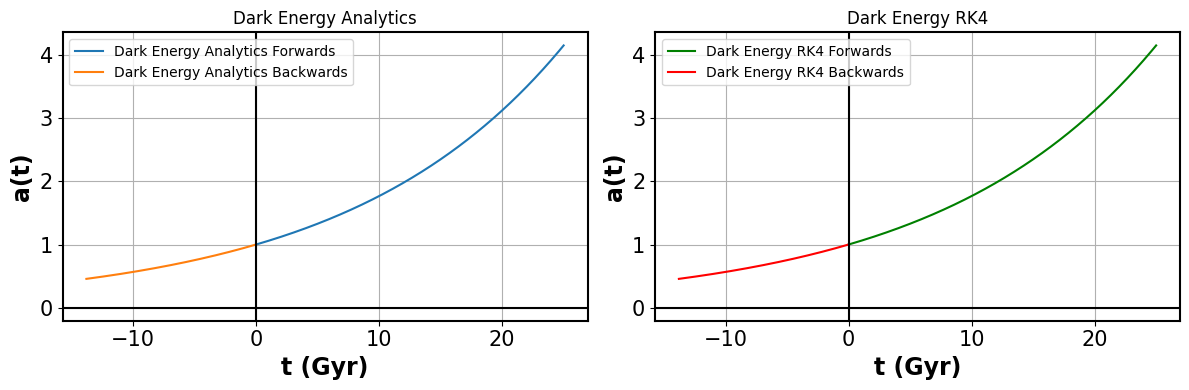

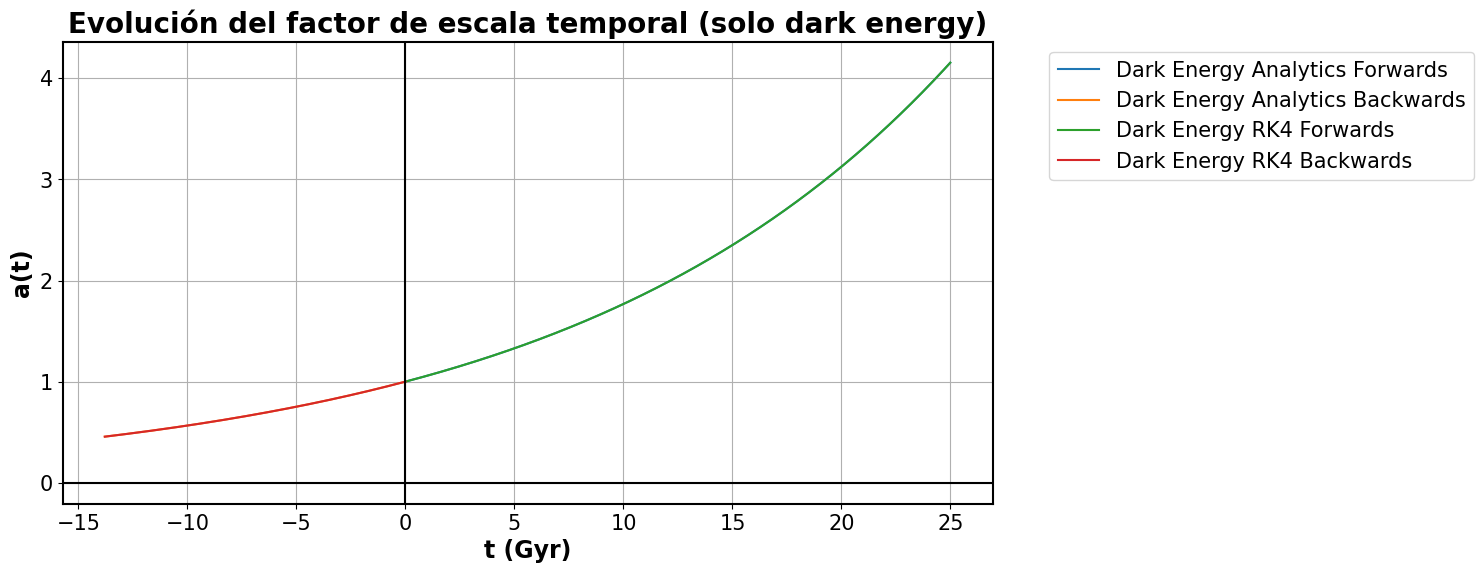

In [6]:
#......................................................
# Resolución para SOLO DARK ENERGY: numérica vs analítica
#......................................................

#---------------------------
# Datos del eje x - temporal 
#---------------------------

t = 0.0  # hoy
dt = 0.01  # 0.01 Gyr = 10 Myr
tF_max = 25.0  # 25 Gyr en el futuro
tB_min = -13.8  # hasta casi el Big Bang
N_F = int((tF_max - t) / dt)
print("N_F:",N_F)
N_B = int((t - tB_min) / dt)
print("N_B:",N_B)

tF = np.arange(0.0, tF_max, dt)
tB = np.arange(0.0, tB_min, -dt)
print("tB:",tB,"\n")

#------------
# Constantes 
#------------

# Usamos pues H_0 del CMB, en Gyr:
H_0 = 67.4 / 3.086e+19 # Unidades: s^-1
print("H_0 en s^-1 =",H_0)
H_0 *= 3600 * 24 * 365 * 10**(9) # Unidades: Gyr^-1
print("H_0 en Gy^-1 =",H_0)
G = 6.67 * 10**(-11) # Unidades: N*m^2/kg^2
ρ_crit0 = 3.0 / (8.0 * math.pi * G) * H_0**2 # Unidades: kg^2/(N*m^2) * Gyr^-2
ρ_crit0 *= 3600 * 24 * 365 * 10**(9) # Unidades: kg/(m*Gyr)
print("\nρ_crit:",ρ_crit0)

# Datos Tabla 2.1 pg 58 Baumann:
Ω_Λ0 = 0.6847
sqrtΩ_Λ0 = math.sqrt(Ω_Λ0)


#---------
# FUNCIÓN: a_punto[i] = H_0 * sqrtΩ[i] * a[i]**(-1/2*(1+3*ω[i]))
#---------

# Resolución ANALÍTICA ---------------
fF = math.e**(H_0 * sqrtΩ_Λ0 * tF)
fB = math.e**(H_0 * sqrtΩ_Λ0 * tB)
#-------------------------------------


#--------------------
# FUNCIÓN A RESOLVER: a_punto = H_0 * sqrtΩ[i] * a[i]**(-1/2*(1+3*ω[i]))
# PARA SOLO DARK ENERGY: a_punto = H_0 * sqrtΩ[i] * a[i]
#--------------------

#---------------------
# Resolución NUMÉRICA
#---------------------

# FORWARDS -----------

a_numF = np.zeros(N_F)
a_numF[0] = 1.0   # empezamos en 1
#a_numF[0] = 1e-6   # empezamos cerca de cero, no en 1    

for i in range(N_F-1):
    aF = a_numF[i]
    k1 = H_0 * sqrtΩ_Λ0 * aF
    k2 = H_0 * sqrtΩ_Λ0 * (aF + 0.5 * dt * k1)
    k3 = H_0 * sqrtΩ_Λ0 * (aF + 0.5 * dt * k2)
    k4 = H_0 * sqrtΩ_Λ0 * (aF + dt * k3)
    #print(f'{k1:.2e}', f'{k2:.2e}', f'{k3:.2e}', f'{k4:.2e}', a)
    a_numF[i+1] = aF + dt * (k1 + 2*k2 + 2*k3 + k4)/6
    
# BACKWARDS---------
a_numB = np.zeros(N_B)
a_numB[0] = 1.0   # empezamos en 1
#a_numB[0] = 1e-6   # empezamos cerca de cero, no en 1
dt=-dt
for i in range(N_B-1):
    aB = a_numB[i]
    k1 = H_0 * sqrtΩ_Λ0 * aB
    k2 = H_0 * sqrtΩ_Λ0 * (aB + 0.5 * dt * k1)
    k3 = H_0 * sqrtΩ_Λ0 * (aB + 0.5 * dt * k2)
    k4 = H_0 * sqrtΩ_Λ0 * (aB + dt * k3)
    #print(f'{k1:.2e}', f'{k2:.2e}', f'{k3:.2e}', f'{k4:.2e}', a)
    a_numB[i+1] = aB + dt * (k1 + 2*k2 + 2*k3 + k4)/6
    

#----------------------------------------
                # PLOT
#----------------------------------------


# GRÁFICAS PARALELAS Y SEPARADAS -------------------------------------------------------------------------------

fig, axs = plt.subplots(1, 2, figsize=(12, 4))

# ---- Gráfica Analítica ----
axs[0].plot(tF, fF, label="Dark Energy Analytics Forwards")
axs[0].plot(tB, fB, label="Dark Energy Analytics Backwards")
axs[0].set_title("Dark Energy Analytics")
axs[0].legend()
axs[0].grid(True)

# ---- Gráfica Numérica ----
axs[1].plot(tF, a_numF, label="Dark Energy RK4 Forwards", color='green')
axs[1].plot(tB, a_numB, label="Dark Energy RK4 Backwards", color='red')
axs[1].set_title("Dark Energy RK4")
axs[1].legend()
axs[1].grid(True)

# ---- Ajustes COMUNES a ambos subplots ----
for ax in axs:
    # Títulos de los ejes
    ax.set_xlabel('t (Gyr)', fontsize=17, fontweight='bold')
    ax.set_ylabel('a(t)', fontsize=17, fontweight='bold')

    # Etiquetas de los ticks
    ax.tick_params(axis='both', labelsize=15)

    # Ejes x=0 e y=0 en negrita
    ax.axhline(0, color='black', linewidth=1.5)
    ax.axvline(0, color='black', linewidth=1.5)

    # Ejes (spines) en negrita
    for spine in ax.spines.values():
        spine.set_linewidth(1.5)

plt.tight_layout()
plt.show()


# GRÁFICA INICIAL CON TODO JUNTO -------------------------------------------------------------------------------

# Tamaño --------------------------------
plt.figure(figsize = (12,6))

# Ploteo --------------------------------
plt.plot(tF, fF, label = "Dark Energy Analytics Forwards")
plt.plot(tB, fB, label = "Dark Energy Analytics Backwards")
plt.plot(tF, a_numF, label = "Dark Energy RK4 Forwards") 
plt.plot(tB, a_numB, label = "Dark Energy RK4 Backwards")

# Título y tamaño de gráfica ------------
plt.title('Evolución del factor de escala temporal (solo dark energy)', 
          fontsize = 20, fontweight = 'bold', color = 'black')

# Títulos de ejes------------------------
plt.xlabel('t (Gyr)', fontsize = 17, fontweight = 'bold', color = 'black')
plt.ylabel('a(t)', fontsize = 17, fontweight = 'bold', color = 'black')

# Etiquetas de los ejes -----------------
    # Tamaño
plt.xticks(fontsize = 15)
plt.yticks(fontsize = 15)

# Trazar los ejes x=0 e y=0 en negrita --
ax = plt.gca()
ax.axhline(0, color = 'black', linewidth = 1.5)
ax.axvline(0, color = 'black', linewidth = 1.5)
for spine in ax.spines.values():
    spine.set_linewidth(1.5)

# Leyenda--------------------------------
plt.legend(fontsize = 15, bbox_to_anchor = (1.05,1), loc = 'upper left')

# Mostrar gráfico -----------------------
plt.grid(True)
plt.show()

### Gráfica soluciones ec Friedmann para Universo 1 componente, todas juntas

['Matter', 'Radiation', 'Dark Energy']
Ω_0 = [0.3153, 9.02e-05, 0.6847]
i = 0 sqrtΩ_0[i] = 0.5615158056546583 

i = 1 sqrtΩ_0[i] = 0.009497368056467012 

i = 2 sqrtΩ_0[i] = 0.8274660113865705 



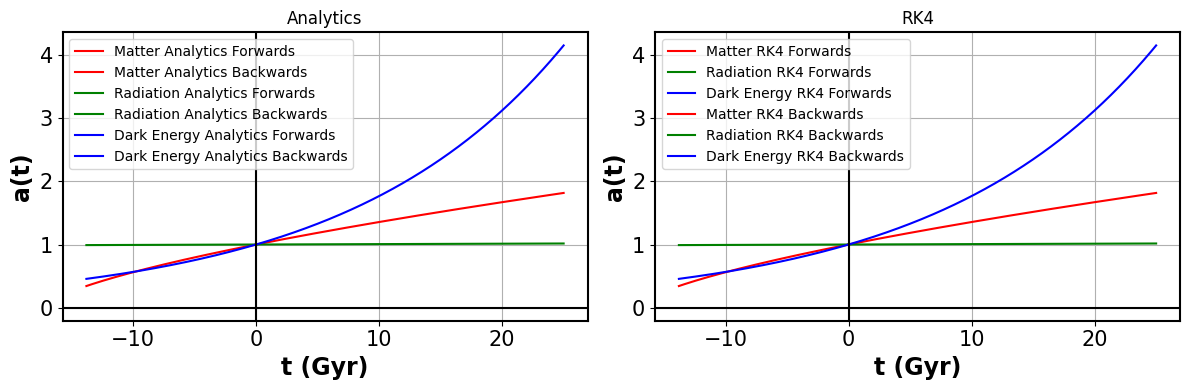

In [7]:
#...................................................................................................
# Resolución para SOLO MATERIA, RADIACIÓN Y DARK ENERGY EN UNA MISMA GRÁFICA: numérica vs analítica
#...................................................................................................

#---------------------------
# Datos del eje x - temporal 
#---------------------------

t = 0.0  # hoy
dt = 0.01  # 0.01 Gyr = 10 Myr
tF_max = 25.0  # 25 Gyr en el futuro
tB_min = -13.8  # hasta casi el Big Bang
N_F = int((tF_max - t) / dt)
#print("N_F:",N_F)
N_B = int((t - tB_min) / dt)
#print("N_B:",N_B)

tF = np.arange(0.0, tF_max, dt)
tB = np.arange(0.0, tB_min, -dt)
#print("tB:",tB,"\n")

#------------
# Constantes 
#------------

# Usamos pues H_0 del CMB, en Gyr:
H_0 = 67.4 / 3.086e+19 # Unidades: s^-1
#print("H_0 en s^-1 =",H_0)
H_0 *= 3600 * 24 * 365 * 10**(9) # Unidades: Gyr^-1
#print("H_0 en Gy^-1 =",H_0)

# Datos Tabla 2.1 pg 58 Baumann:
names = ["Matter", "Radiation", "Dark Energy"]
colors = ["red","green","blue"]
Ω_0 = [0.3153, 9.02e-5, 0.6847]
sqrtΩ_0 = [math.sqrt(0.3153), math.sqrt(9.02e-5), math.sqrt(0.6847)]
ω = np.array([0,1/3,-1])
print(names)
print("Ω_0 =",Ω_0)
for i in range(3):
    print("i =",i,"sqrtΩ_0[i] =",sqrtΩ_0[i],"\n")

#---------
# FUNCIÓN: a_punto[i] = H_0 * sqrtΩ[i] * a[i]**(-1/2*(1+3*ω[i]))
#---------

# Resolución ANALÍTICA ---------------
fF = [(3/2 * H_0 * sqrtΩ_0[0] * tF + 1)**(2/3), (2 * H_0 * sqrtΩ_0[1] * tF + 1)**(1/2), math.e**(H_0 * sqrtΩ_0[2] * tF)]
fB = [(3/2 * H_0 * sqrtΩ_0[0] * tB + 1)**(2/3), (2 * H_0 * sqrtΩ_0[1] * tB + 1)**(1/2), math.e**(H_0 * sqrtΩ_0[2] * tB)]
#-------------------------------------


#--------------------
# FUNCIÓN A RESOLVER: a_punto = H_0 * sqrtΩ[i] * a[i]**(-1/2*(1+3*ω[i]))
# PARA SOLO MATERIA: a_punto = H_0 * sqrtΩ[i] * a[i]**(-1/2)
# PARA SOLO RADIACIÓN: a_punto = H_0 * sqrtΩ[i] * a[i]**(-1)
# PARA SOLO DARK ENERGY: a_punto = H_0 * sqrtΩ[i] * a[i]
#--------------------

#---------------------
# Resolución NUMÉRICA
#---------------------

fig, axs = plt.subplots(1, 2, figsize=(12, 4))

# FORWARDS -----------
for j in range(3):
    a_numF = np.zeros(N_F)
    a_numF[0] = 1.0   # empezamos en 1
    #a_numF[0] = 1e-6   # empezamos cerca de cero, no en 1    
    #print("Valores exponentes de a para w =",ω[j],":",-1/2*(1+3*ω[j]),"\n")
    for i in range(N_F-1):        
        aF = a_numF[i]
        k1 = H_0 * sqrtΩ_0[j] * aF**(-1/2*(1+3*ω[j]))
        k2 = H_0 * sqrtΩ_0[j] * (aF + 0.5 * dt * k1)**(-1/2*(1+3*ω[j]))
        k3 = H_0 * sqrtΩ_0[j] * (aF + 0.5 * dt * k2)**(-1/2*(1+3*ω[j]))
        k4 = H_0 * sqrtΩ_0[j] * (aF + dt * k3)**(-1/2*(1+3*ω[j]))
        #print(f'{k1:.2e}', f'{k2:.2e}', f'{k3:.2e}', f'{k4:.2e}', a)
        a_numF[i+1] = aF + dt * (k1 + 2*k2 + 2*k3 + k4)/6
        
    #if j==1:
    #    print("a_numF[N_F-1]=",a_numF[N_F-1])
            
    axs[1].plot(tF, a_numF, label= f"{names[j]} RK4 Forwards", color=f"{colors[j]}")

    
# BACKWARDS---------
dt=-dt
for j in range(3):
    a_numB = np.zeros(N_B)
    a_numB[0] = 1.0   # empezamos en 1
    #a_numB[0] = 1e-6   # empezamos cerca de cero, no en 1
    for i in range(N_B-1):
        aB = a_numB[i]
        k1 = H_0 * sqrtΩ_0[j] * aB**(-1/2*(1+3*ω[j]))
        k2 = H_0 * sqrtΩ_0[j] * (aB + 0.5 * dt * k1)**(-1/2*(1+3*ω[j]))
        k3 = H_0 * sqrtΩ_0[j] * (aB + 0.5 * dt * k2)**(-1/2*(1+3*ω[j]))
        k4 = H_0 * sqrtΩ_0[j] * (aB + dt * k3)**(-1/2*(1+3*ω[j]))
        #print(f'{k1:.2e}', f'{k2:.2e}', f'{k3:.2e}', f'{k4:.2e}', a)
        a_numB[i+1] = aB + dt * (k1 + 2*k2 + 2*k3 + k4)/6
        
    #if j==1:
    #    print("a_numB[N_B-1]=",a_numB[N_B-1]) #"a_numF[tF_max]=",a_numF[tF_max])
        
    axs[1].plot(tB, a_numB, label= f"{names[j]} RK4 Backwards", color=f"{colors[j]}")

axs[1].set_title("RK4")
#axs[1].set_ylim(0.95,1.05)
#axs[1].legend()
axs[1].legend( loc = 'upper left')
axs[1].grid(True)
    

    
#----------------------------------------
                # PLOT
#----------------------------------------


# GRÁFICAS PARALELAS Y SEPARADAS -------------------------------------------------------------------------------


# ---- Gráfica Analítica ----
for j in range(3):
    axs[0].plot(tF, fF[j], label= f"{names[j]} Analytics Forwards", color=f"{colors[j]}")
    axs[0].plot(tB, fB[j], label= f"{names[j]} Analytics Backwards", color=f"{colors[j]}")
axs[0].set_title("Analytics")
#axs[0].set_ylim(0.95,1.05)
#axs[0].legend()
#axs[0].legend(fontsize = 15, bbox_to_anchor = (1.05,1), loc = 'upper left')
axs[0].legend(loc = 'upper left')
axs[0].grid(True)


# ---- Ajustes COMUNES a ambos subplots ----
for ax in axs:
    # Títulos de los ejes
    ax.set_xlabel('t (Gyr)', fontsize=17, fontweight='bold')
    ax.set_ylabel('a(t)', fontsize=17, fontweight='bold')

    # Etiquetas de los ticks
    ax.tick_params(axis='both', labelsize=15)

    # Ejes x=0 e y=0 en negrita
    ax.axhline(0, color='black', linewidth=1.5)
    ax.axvline(0, color='black', linewidth=1.5)

    # Ejes (spines) en negrita
    for spine in ax.spines.values():
        spine.set_linewidth(1.5)

plt.tight_layout()
plt.show()

['Materia', 'Radiación', 'Dark Energy']
Ω_0 = [0.3153, 9.02e-05, 0.6847]
i = 0 sqrtΩ_0[i] = 0.5615158056546583 

i = 1 sqrtΩ_0[i] = 0.009497368056467012 

i = 2 sqrtΩ_0[i] = 0.8274660113865705 



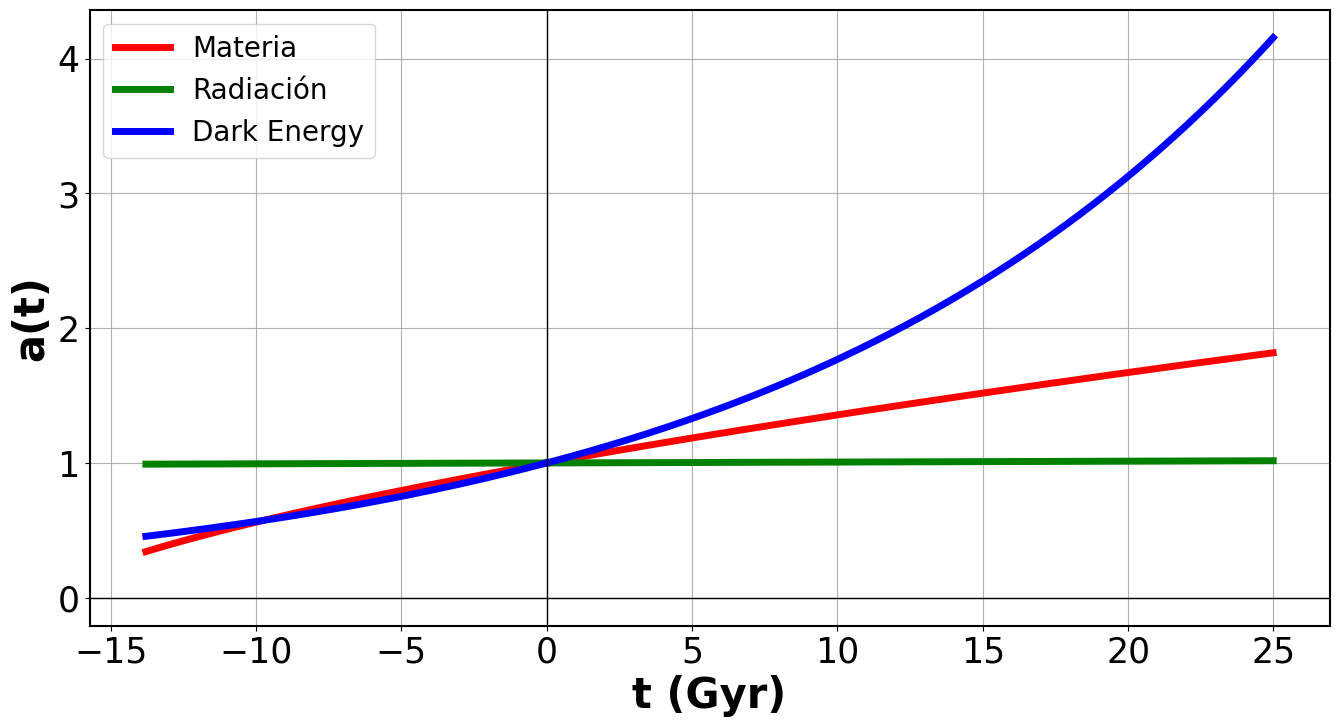

In [8]:
#...................................................................................................
# Resolución para SOLO MATERIA, RADIACIÓN Y DARK ENERGY EN UNA MISMA GRÁFICA: numérica vs analítica
#...................................................................................................

#---------------------------
# Datos del eje x - temporal 
#---------------------------

t = 0.0  # hoy
dt = 0.01  # 0.01 Gyr = 10 Myr
tF_max = 25.0  # 25 Gyr en el futuro
tB_min = -13.8  # hasta casi el Big Bang
N_F = int((tF_max - t) / dt)
#print("N_F:",N_F)
N_B = int((t - tB_min) / dt)
#print("N_B:",N_B)

tF = np.arange(0.0, tF_max, dt)
tB = np.arange(0.0, tB_min, -dt)
#print("tB:",tB,"\n")

#------------
# Constantes 
#------------

# Usamos pues H_0 del CMB, en Gyr:
H_0 = 67.4 / 3.086e+19 # Unidades: s^-1
#print("H_0 en s^-1 =",H_0)
H_0 *= 3600 * 24 * 365 * 10**(9) # Unidades: Gyr^-1
#print("H_0 en Gy^-1 =",H_0)

# Datos Tabla 2.1 pg 58 Baumann:
names = ["Materia", "Radiación", "Dark Energy"]
colors = ["red","green","blue"]
Ω_0 = [0.3153, 9.02e-5, 0.6847]
sqrtΩ_0 = [math.sqrt(0.3153), math.sqrt(9.02e-5), math.sqrt(0.6847)]
ω = np.array([0,1/3,-1])
print(names)
print("Ω_0 =",Ω_0)
for i in range(3):
    print("i =",i,"sqrtΩ_0[i] =",sqrtΩ_0[i],"\n")

#---------
# FUNCIÓN: a_punto[i] = H_0 * sqrtΩ[i] * a[i]**(-1/2*(1+3*ω[i]))
#---------

# Resolución ANALÍTICA ---------------
fF = [(3/2 * H_0 * sqrtΩ_0[0] * tF + 1)**(2/3), (2 * H_0 * sqrtΩ_0[1] * tF + 1)**(1/2), math.e**(H_0 * sqrtΩ_0[2] * tF)]
fB = [(3/2 * H_0 * sqrtΩ_0[0] * tB + 1)**(2/3), (2 * H_0 * sqrtΩ_0[1] * tB + 1)**(1/2), math.e**(H_0 * sqrtΩ_0[2] * tB)]
#-------------------------------------


#--------------------
# FUNCIÓN A RESOLVER: a_punto = H_0 * sqrtΩ[i] * a[i]**(-1/2*(1+3*ω[i]))
# PARA SOLO MATERIA: a_punto = H_0 * sqrtΩ[i] * a[i]**(-1/2)
# PARA SOLO RADIACIÓN: a_punto = H_0 * sqrtΩ[i] * a[i]**(-1)
# PARA SOLO DARK ENERGY: a_punto = H_0 * sqrtΩ[i] * a[i]
#--------------------

#---------------------
# Resolución NUMÉRICA
#---------------------

#fig, axs = plt.subplots(1, 2, figsize=(12, 4))
# Tamaño gráfica
plt.figure(figsize = (16, 8))

# FORWARDS -----------
for j in range(3):
    a_numF = np.zeros(N_F)
    a_numF[0] = 1.0   # empezamos en 1
    #a_numF[0] = 1e-6   # empezamos cerca de cero, no en 1    
    #print("Valores exponentes de a para w =",ω[j],":",-1/2*(1+3*ω[j]),"\n")
    for i in range(N_F-1):        
        aF = a_numF[i]
        k1 = H_0 * sqrtΩ_0[j] * aF**(-1/2*(1+3*ω[j]))
        k2 = H_0 * sqrtΩ_0[j] * (aF + 0.5 * dt * k1)**(-1/2*(1+3*ω[j]))
        k3 = H_0 * sqrtΩ_0[j] * (aF + 0.5 * dt * k2)**(-1/2*(1+3*ω[j]))
        k4 = H_0 * sqrtΩ_0[j] * (aF + dt * k3)**(-1/2*(1+3*ω[j]))
        #print(f'{k1:.2e}', f'{k2:.2e}', f'{k3:.2e}', f'{k4:.2e}', a)
        a_numF[i+1] = aF + dt * (k1 + 2*k2 + 2*k3 + k4)/6
        
    #if j==1:
        #print("a_numF=",a_numF[2599])
        #print("a_numF["f"{N_F-1}""]=",a_numF[N_F-1])
        #print("t=",tF[N_F-1])
            
    plt.plot(tF, a_numF, label= f"{names[j]}", color=f"{colors[j]}", lw=5)

    
# BACKWARDS---------
dt=-dt
for j in range(3):
    a_numB = np.zeros(N_B)
    a_numB[0] = 1.0   # empezamos en 1
    #a_numB[0] = 1e-6   # empezamos cerca de cero, no en 1
    for i in range(N_B-1):
        aB = a_numB[i]
        k1 = H_0 * sqrtΩ_0[j] * aB**(-1/2*(1+3*ω[j]))
        k2 = H_0 * sqrtΩ_0[j] * (aB + 0.5 * dt * k1)**(-1/2*(1+3*ω[j]))
        k3 = H_0 * sqrtΩ_0[j] * (aB + 0.5 * dt * k2)**(-1/2*(1+3*ω[j]))
        k4 = H_0 * sqrtΩ_0[j] * (aB + dt * k3)**(-1/2*(1+3*ω[j]))
        #print(f'{k1:.2e}', f'{k2:.2e}', f'{k3:.2e}', f'{k4:.2e}', a)
        a_numB[i+1] = aB + dt * (k1 + 2*k2 + 2*k3 + k4)/6
        
    #if j==1:
    #    print("a_numB[N_B-1]=",a_numB[N_B-1]) #"a_numF[tF_max]=",a_numF[tF_max])
        
    plt.plot(tB, a_numB, color=f"{colors[j]}", lw=5)

    

    
#----------------------------------------
                # PLOT
#----------------------------------------

# Título y tamaño de gráfica
#plt.title('Evolución del factor de escala temporal para un Universo de solo materia, radiación o energía oscura con el tiempo en Gyr', fontsize = 20, fontweight = 'bold', color = 'black')

# Títulos de ejes
plt.xlabel('t (Gyr)', fontsize = 30, fontweight = 'bold', color = 'black')
plt.ylabel('a(t)', fontsize = 30, fontweight = 'bold', color = 'black')

# Etiquetas de los ejes
    # Tamaño
plt.xticks(fontsize = 25)
plt.yticks(fontsize = 25) 

# Trazar los ejes x=0 e y=0 en negrita
ax = plt.gca()
ax.axhline(0, color = 'black', linewidth = 1.0)
ax.axvline(0, color = 'black', linewidth = 1.0)
for spine in ax.spines.values():
    spine.set_linewidth(1.5)
#plt.axhline(1, color='lightgray', linestyle='-', label=f"hoy (a={a_present:.2f})")

# Leyenda
plt.legend(fontsize = 20)
#plt.legend(fontsize = 15, bbox_to_anchor = (1.05,1), loc = 'upper left')

# Guardar figura
plt.grid(True, which = 'both')
plt.savefig("Fig2_a(t).png")

# Mostrar gráfico
plt.show()

### Soluciones de Universos combinadas: MATERIA + DARK ENERGY (modelo ΛCDM):

#### Resolución NUMÉRICA ΛCDM para MATERIA Y DARK ENERGY

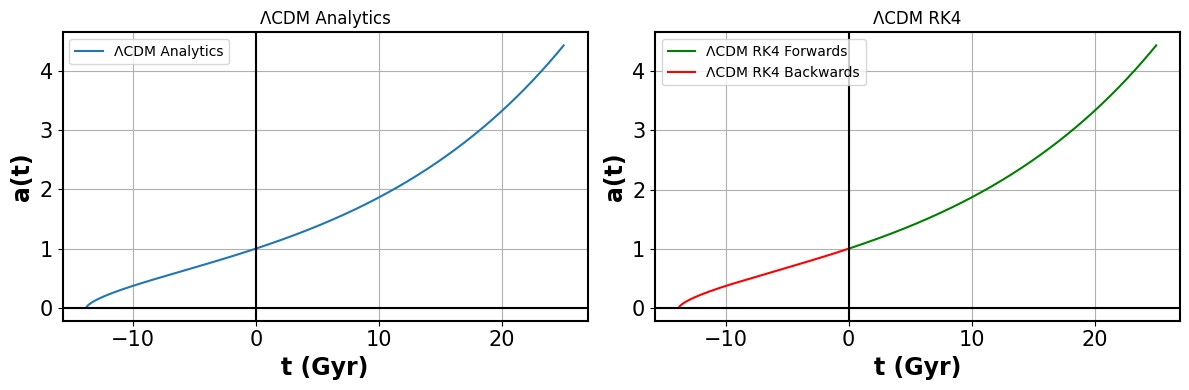

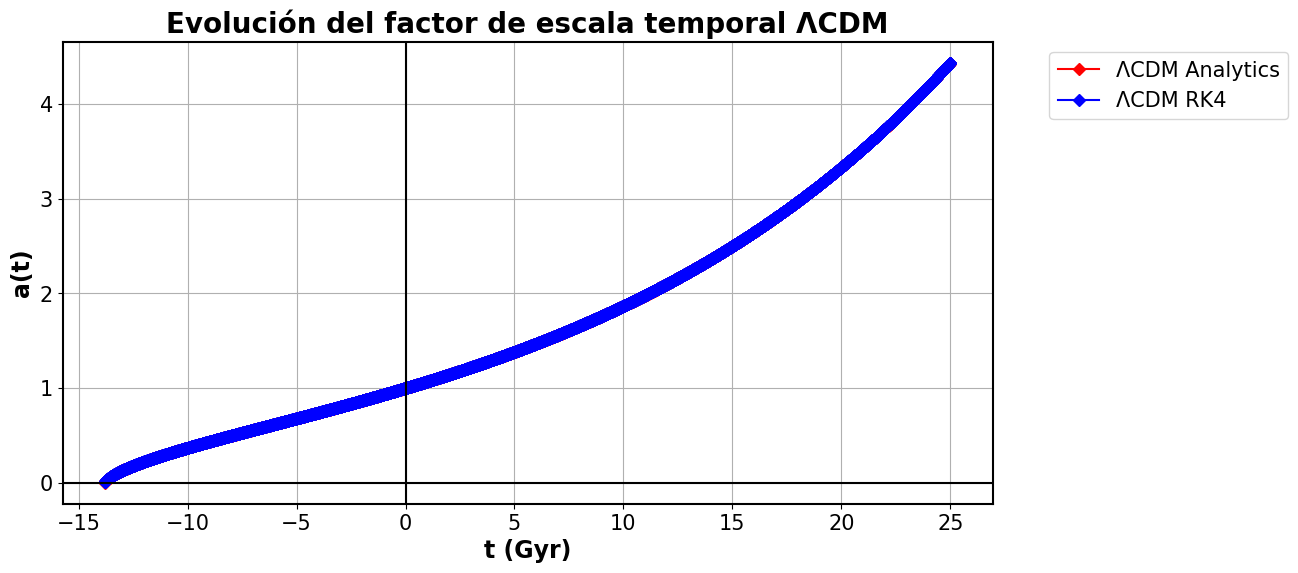

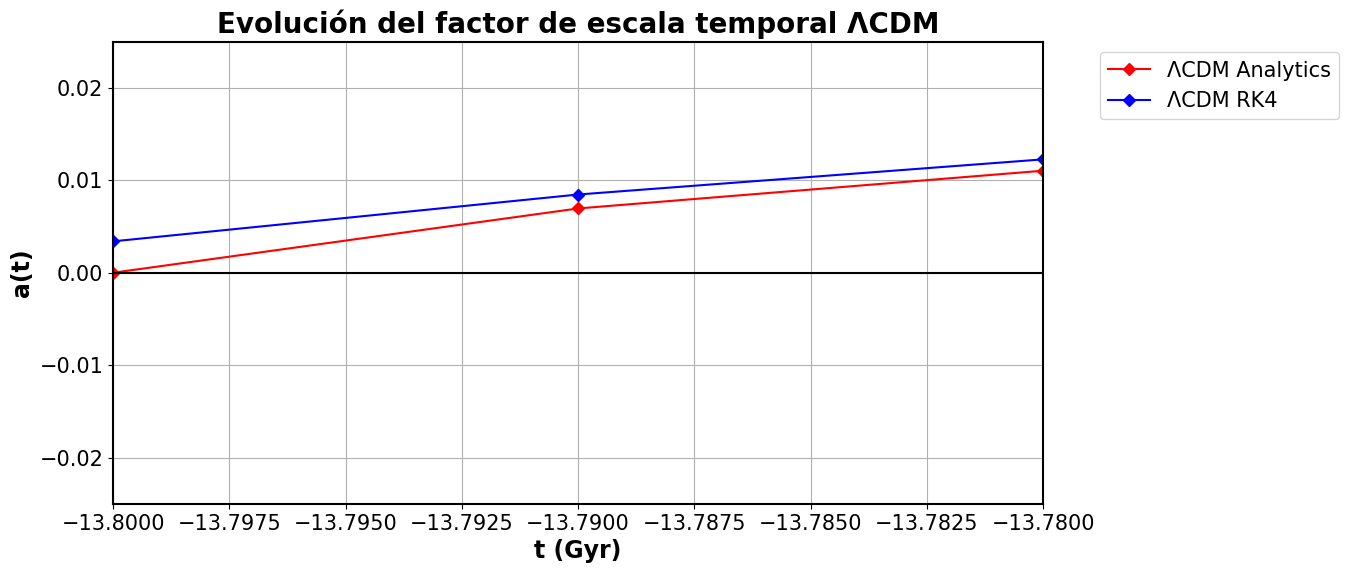

In [9]:
#.......................................................
# Resolución NUMÉRICA ΛCDM para MATERIA Y DARK ENERGY 
#.......................................................

#---------------------------
# Datos del eje x - temporal 
#---------------------------

t = 0.0  # hoy
dt = 0.01  # 0.01 Gyr = 10 Myr
tF_max = 25.0  # 25 Gyr en el futuro
tB_min = -13.8  # hasta casi el Big Bang
N_F = int((tF_max - t) / dt)
#print("N_F:",N_F)
N_B = int((t - tB_min) / dt)
#print("N_B:",N_B)

tF = np.arange(0.0, tF_max+0.01, dt)
tB = np.arange(0.0, tB_min-0.01, -dt)
tA = np.arange(0.0, tF_max-tB_min+0.01, dt) # tiempo para la función analítica

N_F = N_F + 1
N_B = N_B + 1

#------------
# Constantes 
#------------

# Usamos pues H_0 del CMB, en Gyr:
H_0 = 67.4 / 3.086e+19 # Unidades: s^-1
#print("H_0 en s^-1 =",H_0)
H_0 *= 3600 * 24 * 365 * 10**(9) # Unidades: Gyr^-1
#print("H_0 en Gy^-1 =",H_0)

# Datos Tabla 2.1 pg 58 Baumann:
names = ["Matter", "Radiation", "Dark Energy"]
colors = ["red","green","blue"]
Ω_0 = [0.3153, 9.02e-5, 0.6847]
sqrtΩ_0 = [math.sqrt(0.3153), math.sqrt(9.02e-5), math.sqrt(0.6847)]
ω = np.array([0,1/3,-1])
#print(names)
#print("Ω_0=",Ω_0)
#for i in range(3):
#    print("i=",i,"sqrtΩ_0[i]=",sqrtΩ_0[i],"\n")

#---------
# FUNCIÓN: a_punto = H_0 * a * (Ω_0[0] * a**(-3*(1+ω[0])) + Ω_0[2] * a**(-3*(1+ω[2])))**(1/2)
# a_punto = H_0 * a * (Ω_0[0] * a**(-3) + Ω_0[2])**(1/2)
#---------

#----------------------
# Resolución ANALÍTICA
#----------------------

# SEGÚN BAUMANN: a(t) = (Ω_0[0]/Ω_0[2])**(1/3) * math.sinh(3/2 * sqrtΩ_0[2] * H_0 * t)
# at early times: a(t) \sim t**(2/3)

fA = (Ω_0[0]/Ω_0[2])**(1/3) * np.cbrt(np.sinh(3/2 * sqrtΩ_0[2] * H_0 * tA))**2 # cálculo de la función analítica desde t=0 hasta t=25.0+13.8 Gyr
tA += tB_min # desplazamiento de la gráfica para que vaya desde t=-13.8 Gyr hasta t=25.0 Gyr 

#----------------------
# Resolución NUMÉRICA
#----------------------


# FORWARDS -----------
for j in range(3):
    a_numF_ΛCDM = np.zeros(N_F)
    a_numF_ΛCDM[0] = 1.0   # empezamos en 1
    #a_numF_ΛCDM[0] = 1e-6   # empezamos cerca de cero, no en 1    
    for i in range(N_F-1):        
        aF = a_numF_ΛCDM[i]
        k1 = H_0 * aF * (Ω_0[0] * aF**(-3*(1+ω[0])) + Ω_0[2] * aF**(-3*(1+ω[2])))**(1/2)
        k2 = H_0 * (aF + 0.5 * dt * k1) * (Ω_0[0] * (aF + 0.5 * dt * k1)**(-3*(1+ω[0])) + Ω_0[2] * (aF + 0.5 * dt * k1)**(-3*(1+ω[2])))**(1/2)
        k3 = H_0 * (aF + 0.5 * dt * k2) * (Ω_0[0] * (aF + 0.5 * dt * k2)**(-3*(1+ω[0])) + Ω_0[2] * (aF + 0.5 * dt * k2)**(-3*(1+ω[2])))**(1/2)
        k4 = H_0 * (aF + dt * k3) * (Ω_0[0] * (aF + dt * k3)**(-3*(1+ω[0])) + Ω_0[2] * (aF + dt * k3)**(-3*(1+ω[2])))**(1/2)
        #print(f'{k1:.2e}', f'{k2:.2e}', f'{k3:.2e}', f'{k4:.2e}', a)
        a_numF_ΛCDM[i+1] = aF + dt * (k1 + 2*k2 + 2*k3 + k4)/6
            
# BACKWARDS---------
dt=-dt
for j in range(3):
    a_numB_ΛCDM = np.zeros(N_B)
    a_numB_ΛCDM[0] = 1.0   # empezamos en 1
    #a_numB_ΛCDM[0] = 1e-6   # empezamos cerca de cero, no en 1
    for i in range(N_B-1):
        aB = a_numB_ΛCDM[i]
        k1 = H_0 * aB * (Ω_0[0] * aB**(-3*(1+ω[0])) + Ω_0[2] * aB**(-3*(1+ω[2])))**(1/2)
        k2 = H_0 * (aB + 0.5 * dt * k1) * (Ω_0[0] * (aB + 0.5 * dt * k1)**(-3*(1+ω[0])) + Ω_0[2] * (aB + 0.5 * dt * k1)**(-3*(1+ω[2])))**(1/2)
        k3 = H_0 * (aB + 0.5 * dt * k2) * (Ω_0[0] * (aB + 0.5 * dt * k2)**(-3*(1+ω[0])) + Ω_0[2] * (aB + 0.5 * dt * k2)**(-3*(1+ω[2])))**(1/2)
        k4 = H_0 * (aB + dt * k3) * (Ω_0[0] * (aB + dt * k3)**(-3*(1+ω[0])) + Ω_0[2] * (aB + dt * k3)**(-3*(1+ω[2])))**(1/2)
        #print(f'{k1:.2e}', f'{k2:.2e}', f'{k3:.2e}', f'{k4:.2e}', a)
        a_numB_ΛCDM[i+1] = aB + dt * (k1 + 2*k2 + 2*k3 + k4)/6
        
    
#----------------------------------------
                # PLOT
#----------------------------------------

# GRÁFICAS PARALELAS Y SEPARADAS -------------------------------------------------------------------------------

fig, axs = plt.subplots(1, 2, figsize=(12, 4))

# ---- Gráfica Analítica ----
axs[0].plot(tA, fA, label="ΛCDM Analytics")
axs[0].set_title("ΛCDM Analytics")
axs[0].legend()
axs[0].grid(True)

# ---- Gráfica Numérica ----
axs[1].plot(tF, a_numF_ΛCDM, label="ΛCDM RK4 Forwards", color='green')
axs[1].plot(tB, a_numB_ΛCDM, label="ΛCDM RK4 Backwards", color='red')
axs[1].set_title("ΛCDM RK4")
axs[1].legend()
axs[1].grid(True)

# ---- Ajustes COMUNES a ambos subplots ----
for ax in axs:
    # Títulos de los ejes
    ax.set_xlabel('t (Gyr)', fontsize=17, fontweight='bold')
    ax.set_ylabel('a(t)', fontsize=17, fontweight='bold')

    # Etiquetas de los ticks
    ax.tick_params(axis='both', labelsize=15)

    # Ejes x=0 e y=0 en negrita
    ax.axhline(0, color='black', linewidth=1.5)
    ax.axvline(0, color='black', linewidth=1.5)

    # Ejes (spines) en negrita
    for spine in ax.spines.values():
        spine.set_linewidth(1.5)

plt.tight_layout()
plt.show()


# GRÁFICA INICIAL CON TODO JUNTO -------------------------------------------------------------------------------

# ZONA FORWARDS ...................................................................................................................................

# Tamaño --------------------------------
plt.figure(figsize = (12,6))

# Ploteo --------------------------------

plt.plot(tA, fA, label = "ΛCDM Analytics", marker='D', color = "red")
#plt.plot(tB, fB, color = "red")
plt.plot(tF, a_numF_ΛCDM, label = "ΛCDM RK4", marker='D', color = "blue") 
plt.plot(tB, a_numB_ΛCDM, marker='D', color = "blue")

#plt.plot(tF, fF, label = "ΛCDM Analytics Forwards", color = "red")
#plt.plot(tB, fB, label = "ΛCDM Analytics Backwards", color = "red")
#plt.plot(tF, a_numF, label = "ΛCDM RK4 Forwards", color = "blue") 
#plt.plot(tB, a_numB, label = "ΛCDM RK4 Backwards", color = "blue")

# Título y tamaño de gráfica ------------
plt.title('Evolución del factor de escala temporal ΛCDM', 
          fontsize = 20, fontweight = 'bold', color = 'black')

# Títulos de ejes------------------------
plt.xlabel('t (Gyr)', fontsize = 17, fontweight = 'bold', color = 'black')
plt.ylabel('a(t)', fontsize = 17, fontweight = 'bold', color = 'black')

# Etiquetas de los ejes -----------------
    # Tamaño
plt.xticks(fontsize = 15)
plt.yticks(fontsize = 15)

# Trazar los ejes x=0 e y=0 en negrita --
ax = plt.gca()
ax.axhline(0, color = 'black', linewidth = 1.5)
ax.axvline(0, color = 'black', linewidth = 1.5)
for spine in ax.spines.values():
    spine.set_linewidth(1.5)
#ax.set_xlim(-13.8,-13.78)
#ax.set_ylim(-0.025,0.025)
#ax.set_xlim(49.92,50.05)
#ax.set_ylim(18.35,18.5)

# Leyenda--------------------------------
plt.legend(fontsize = 15, bbox_to_anchor = (1.05,1), loc = 'upper left')

# Mostrar gráfico -----------------------
plt.grid(True)
plt.show()

# ZONA BACKWARDS ..................................................................................................................................

# Tamaño --------------------------------
plt.figure(figsize = (12,6))

# Ploteo --------------------------------

plt.plot(tA, fA, label = "ΛCDM Analytics", marker='D', color = "red")
#plt.plot(tB, fB, color = "red")
plt.plot(tF, a_numF_ΛCDM, label = "ΛCDM RK4", marker='D', color = "blue") 
plt.plot(tB, a_numB_ΛCDM, marker='D', color = "blue")

#plt.plot(tF, fF, label = "ΛCDM Analytics Forwards", color = "red")
#plt.plot(tB, fB, label = "ΛCDM Analytics Backwards", color = "red")
#plt.plot(tF, a_numF, label = "ΛCDM RK4 Forwards", color = "blue") 
#plt.plot(tB, a_numB, label = "ΛCDM RK4 Backwards", color = "blue")

# Título y tamaño de gráfica ------------
plt.title('Evolución del factor de escala temporal ΛCDM', 
          fontsize = 20, fontweight = 'bold', color = 'black')

# Títulos de ejes------------------------
plt.xlabel('t (Gyr)', fontsize = 17, fontweight = 'bold', color = 'black')
plt.ylabel('a(t)', fontsize = 17, fontweight = 'bold', color = 'black')

# Etiquetas de los ejes -----------------
    # Tamaño
plt.xticks(fontsize = 15)
plt.yticks(fontsize = 15)

# Trazar los ejes x=0 e y=0 en negrita --
ax = plt.gca()
ax.axhline(0, color = 'black', linewidth = 1.5)
ax.axvline(0, color = 'black', linewidth = 1.5)
for spine in ax.spines.values():
    spine.set_linewidth(1.5)
ax.set_xlim(-13.8,-13.78)
ax.set_ylim(-0.025,0.025)
#ax.set_xlim(49.92,50.05)
#ax.set_ylim(18.35,18.5)

# Leyenda--------------------------------
plt.legend(fontsize = 15, bbox_to_anchor = (1.05,1), loc = 'upper left')

# Mostrar gráfico -----------------------
plt.grid(True)
plt.show()

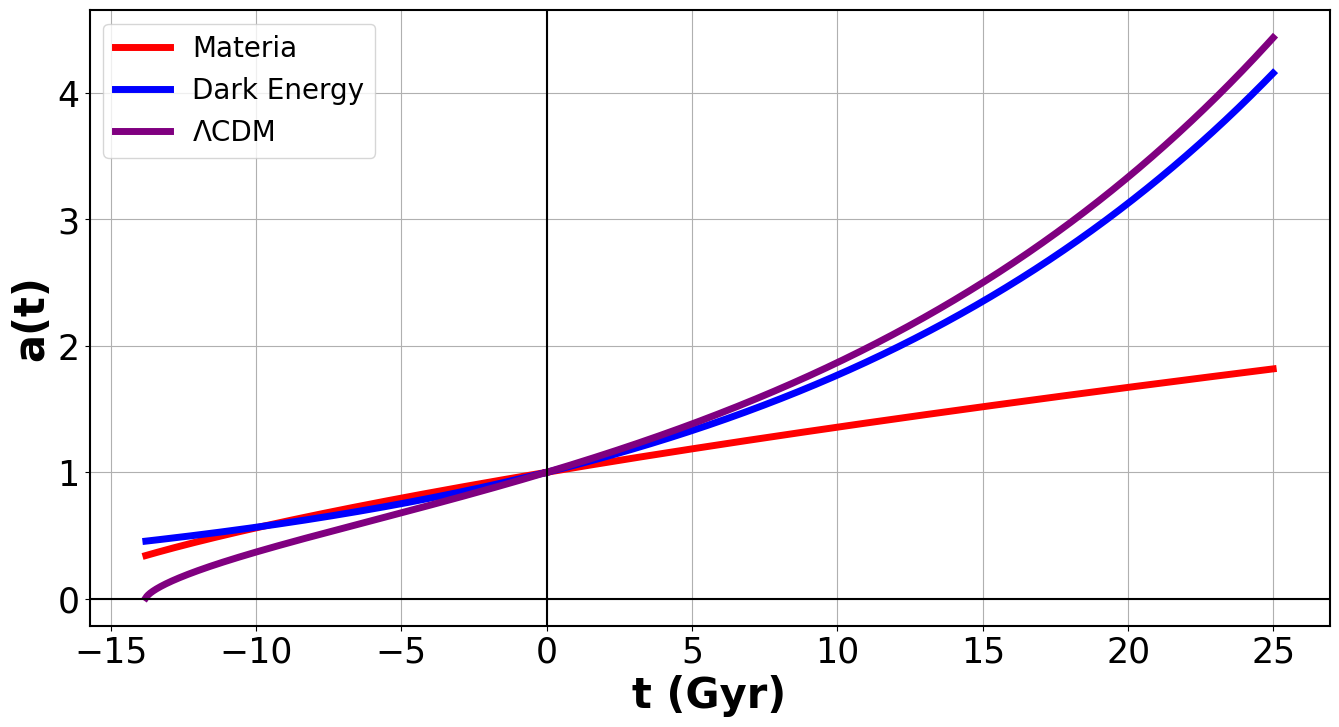

In [10]:
#.......................................................................................................
# Resolución NUMÉRICA ΛCDM para MATERIA Y DARK ENERGY  Y COMPARATIVA CON SOLO MATTER Y SOLO DARK ENERGY
#.......................................................................................................

#---------------------------
# Datos del eje x - temporal 
#---------------------------

t = 0.0  # hoy
dt = 0.01  # 0.01 Gyr = 10 Myr
tF_max = 25.0  # 25 Gyr en el futuro
tB_min = -13.8  # hasta casi el Big Bang
N_F = int((tF_max - t) / dt)
#print("N_F:",N_F)
N_B = int((t - tB_min) / dt)
#print("N_B:",N_B)

tF = np.arange(0.0, tF_max, dt)
tB = np.arange(0.0, tB_min, -dt)
#tA= np.arange(0.0, tF_max-tB_min, dt) # tiempo para la función analítica

#print("tB:",tB,"\n")

#------------
# Constantes 
#------------

# Usamos pues H_0 del CMB, en Gyr:
H_0 = 67.4 / 3.086e+19 # Unidades: s^-1
#print("H_0 en s^-1 =",H_0)
H_0 *= 3600 * 24 * 365 * 10**(9) # Unidades: Gyr^-1
#print("H_0 en Gy^-1 =",H_0)

#Datos Tabla 2.1 pg 58 Baumann:
#names = ["a_matter", "a_rad", "a_Λ"]
#colors = ["red","green","blue"]
#Ω_0 = [0.3153, 9.02e-5, 0.6847]
#sqrtΩ_0 = [math.sqrt(0.3153), math.sqrt(9.02e-5), math.sqrt(0.6847)]
#ω = np.array([0,1/3,-1])

names = ["Materia","Dark Energy"]
colors = ["red", "blue"]
Ω_0 = [0.3153, 0.6847]
sqrtΩ_0 = [math.sqrt(0.3153), math.sqrt(0.6847)]
ω = np.array([0,-1])
#print(names)

# MATTER Y DARK ENERGY POR SEPARADO --------------------------------------------------------------------------------------------------------------------

#---------
# FUNCIÓN: a_punto[i] = H_0 * sqrtΩ[i] * a[i]**(-1/2*(1+3*ω[i]))
#---------

#--------------------
# FUNCIÓN A RESOLVER: a_punto = H_0 * sqrtΩ[i] * a[i]**(-1/2*(1+3*ω[i]))
# PARA SOLO MATERIA: a_punto = H_0 * sqrtΩ[i] * a[i]**(-1/2)
# PARA SOLO RADIACIÓN: a_punto = H_0 * sqrtΩ[i] * a[i]**(-1)
# PARA SOLO DARK ENERGY: a_punto = H_0 * sqrtΩ[i] * a[i]
#--------------------

#---------------------
# Resolución NUMÉRICA
#---------------------

#fig, axs = plt.subplots(1, 2, figsize=(12, 4))
# Tamaño gráfica
plt.figure(figsize = (16, 8))

# FORWARDS -----------
for j in range(2):
    a_numF = np.zeros(N_F)
    a_numF[0] = 1.0   # empezamos en 1
    #a_numF[0] = 1e-6   # empezamos cerca de cero, no en 1    
    #print("Valores exponentes de a para w =",ω[j],":",-1/2*(1+3*ω[j]),"\n")
    for i in range(N_F-1):        
        aF = a_numF[i]
        k1 = H_0 * sqrtΩ_0[j] * aF**(-1/2*(1+3*ω[j]))
        k2 = H_0 * sqrtΩ_0[j] * (aF + 0.5 * dt * k1)**(-1/2*(1+3*ω[j]))
        k3 = H_0 * sqrtΩ_0[j] * (aF + 0.5 * dt * k2)**(-1/2*(1+3*ω[j]))
        k4 = H_0 * sqrtΩ_0[j] * (aF + dt * k3)**(-1/2*(1+3*ω[j]))
        #print(f'{k1:.2e}', f'{k2:.2e}', f'{k3:.2e}', f'{k4:.2e}', a)
        a_numF[i+1] = aF + dt * (k1 + 2*k2 + 2*k3 + k4)/6
        
    #if j==1:
        #print("a_numF=",a_numF[2599])
        #print("a_numF["f"{N_F-1}""]=",a_numF[N_F-1])
        #print("t=",tF[N_F-1])
            
    plt.plot(tF, a_numF, label= f"{names[j]}", color=f"{colors[j]}", lw=5)

    
# BACKWARDS---------
dt=-dt
for j in range(2):
    a_numB = np.zeros(N_B)
    a_numB[0] = 1.0   # empezamos en 1
    #a_numB[0] = 1e-6   # empezamos cerca de cero, no en 1
    for i in range(N_B-1):
        aB = a_numB[i]
        k1 = H_0 * sqrtΩ_0[j] * aB**(-1/2*(1+3*ω[j]))
        k2 = H_0 * sqrtΩ_0[j] * (aB + 0.5 * dt * k1)**(-1/2*(1+3*ω[j]))
        k3 = H_0 * sqrtΩ_0[j] * (aB + 0.5 * dt * k2)**(-1/2*(1+3*ω[j]))
        k4 = H_0 * sqrtΩ_0[j] * (aB + dt * k3)**(-1/2*(1+3*ω[j]))
        #print(f'{k1:.2e}', f'{k2:.2e}', f'{k3:.2e}', f'{k4:.2e}', a)
        a_numB[i+1] = aB + dt * (k1 + 2*k2 + 2*k3 + k4)/6
        
    #if j==1:
    #    print("a_numB[N_B-1]=",a_numB[N_B-1]) #"a_numF[tF_max]=",a_numF[tF_max])
        
    plt.plot(tB, a_numB, color=f"{colors[j]}", lw=5)

    
# ΛCDM -------------------------------------------------------------------------------------------------------------------------------------------------

#---------
# FUNCIÓN: a_punto = H_0 * a * (Ω_0[0] * a**(-3*(1+ω[0])) + Ω_0[2] * a**(-3*(1+ω[2])))**(1/2)
# a_punto = H_0 * a * (Ω_0[0] * a**(-3) + Ω_0[2])**(1/2)
#---------

Ω_0 = [0.3153, 9.02e-5, 0.6847]
sqrtΩ_0 = [math.sqrt(0.3153), math.sqrt(9.02e-5), math.sqrt(0.6847)]
ω = np.array([0,1/3,-1])

#----------------------
# Resolución NUMÉRICA
#----------------------

# FORWARDS -----------
dt=-dt
for j in range(3):
    a_numF_ΛCDM = np.zeros(N_F)
    a_numF_ΛCDM[0] = 1.0   # empezamos en 1
    #a_numF_ΛCDM[0] = 1e-6   # empezamos cerca de cero, no en 1    
    for i in range(N_F-1):        
        aF = a_numF_ΛCDM[i]
        k1 = H_0 * aF * (Ω_0[0] * aF**(-3*(1+ω[0])) + Ω_0[2] * aF**(-3*(1+ω[2])))**(1/2)
        k2 = H_0 * (aF + 0.5 * dt * k1) * (Ω_0[0] * (aF + 0.5 * dt * k1)**(-3*(1+ω[0])) + Ω_0[2] * (aF + 0.5 * dt * k1)**(-3*(1+ω[2])))**(1/2)
        k3 = H_0 * (aF + 0.5 * dt * k2) * (Ω_0[0] * (aF + 0.5 * dt * k2)**(-3*(1+ω[0])) + Ω_0[2] * (aF + 0.5 * dt * k2)**(-3*(1+ω[2])))**(1/2)
        k4 = H_0 * (aF + dt * k3) * (Ω_0[0] * (aF + dt * k3)**(-3*(1+ω[0])) + Ω_0[2] * (aF + dt * k3)**(-3*(1+ω[2])))**(1/2)
        #print(f'{k1:.2e}', f'{k2:.2e}', f'{k3:.2e}', f'{k4:.2e}', a)
        a_numF_ΛCDM[i+1] = aF + dt * (k1 + 2*k2 + 2*k3 + k4)/6
            
# BACKWARDS---------
dt=-dt
for j in range(3):
    a_numB_ΛCDM = np.zeros(N_B)
    a_numB_ΛCDM[0] = 1.0   # empezamos en 1
    #a_numB_ΛCDM[0] = 1e-6   # empezamos cerca de cero, no en 1
    for i in range(N_B-1):
        aB = a_numB_ΛCDM[i]
        k1 = H_0 * aB * (Ω_0[0] * aB**(-3*(1+ω[0])) + Ω_0[2] * aB**(-3*(1+ω[2])))**(1/2)
        k2 = H_0 * (aB + 0.5 * dt * k1) * (Ω_0[0] * (aB + 0.5 * dt * k1)**(-3*(1+ω[0])) + Ω_0[2] * (aB + 0.5 * dt * k1)**(-3*(1+ω[2])))**(1/2)
        k3 = H_0 * (aB + 0.5 * dt * k2) * (Ω_0[0] * (aB + 0.5 * dt * k2)**(-3*(1+ω[0])) + Ω_0[2] * (aB + 0.5 * dt * k2)**(-3*(1+ω[2])))**(1/2)
        k4 = H_0 * (aB + dt * k3) * (Ω_0[0] * (aB + dt * k3)**(-3*(1+ω[0])) + Ω_0[2] * (aB + dt * k3)**(-3*(1+ω[2])))**(1/2)
        #print(f'{k1:.2e}', f'{k2:.2e}', f'{k3:.2e}', f'{k4:.2e}', a)
        a_numB_ΛCDM[i+1] = aB + dt * (k1 + 2*k2 + 2*k3 + k4)/6


#----------------------------------------
                # PLOT
#----------------------------------------

# Título y tamaño de gráfica
#plt.title('Evolución del factor de escala temporal para un Universo de solo materia o solo energía oscura vs modelo ΛCDM con el tiempo en Gyr', 
#          fontsize = 20, fontweight = 'bold', color = 'black')

plt.plot(tF, a_numF_ΛCDM, label="ΛCDM", color='purple', lw=5)
plt.plot(tB, a_numB_ΛCDM, color='purple', lw=5)

# Títulos de ejes
plt.xlabel('t (Gyr)', fontsize = 30, fontweight = 'bold', color = 'black')
plt.ylabel('a(t)', fontsize = 30, fontweight = 'bold', color = 'black')

# Etiquetas de los ejes
    # Tamaño
plt.xticks(fontsize = 25)
plt.yticks(fontsize = 25) 

# Trazar los ejes x=0 e y=0 en negrita --
ax = plt.gca()
ax.axhline(0, color = 'black', linewidth = 1.5)
ax.axvline(0, color = 'black', linewidth = 1.5)
for spine in ax.spines.values():
    spine.set_linewidth(1.5)
#plt.axhline(1, color='lightgray', linestyle='-', label=f"hoy (a={a_present:.2f})")

# Leyenda
plt.legend(fontsize = 20)
#plt.legend(fontsize = 15, bbox_to_anchor = (1.05,1), loc = 'upper left')

# Guardar figura
plt.grid(True, which = 'both')
plt.savefig("Fig3_a(t)_ΛCDM.png")

# Mostrar gráfico
plt.show()

### Resolución NUMÉRICA ω0ωaCDM

C:\Users\mprqu\AppData\Local\Temp\ipykernel_33928\1927487857.py:82: RuntimeWarning: invalid value encountered in scalar power
  k3 = H_0 * math.sqrt(Ω_0[0] / (aB + 0.5 * dt * k2) + (1-Ω_0[0]) *  (aB + 0.5 * dt * k2)**(-1 - 3 * (ω0 + ωa * (1-(aB + 0.5 * dt * k2)))))


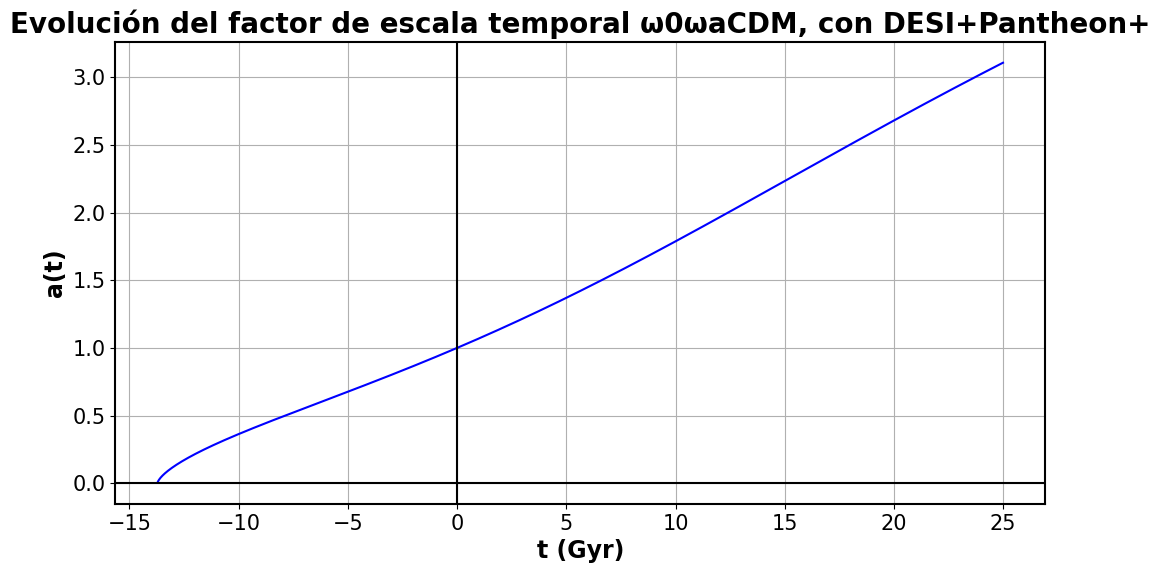

In [11]:
#...............................
# Resolución NUMÉRICA ω0ωaCDM
#...............................

#---------------------------
# Datos del eje x - temporal 
#---------------------------

t = 0.0  # hoy
dt = 0.01  # 0.01 Gyr = 10 Myr
tF_max = 25.0  # 25 Gyr en el futuro
tB_min = -13.8  # hasta casi el Big Bang
N_F = int((tF_max - t) / dt)
#print("N_F:",N_F)
N_B = int((t - tB_min) / dt)
#print("N_B:",N_B)

tF = np.arange(0.0, tF_max, dt)
tB = np.arange(0.0, tB_min, -dt)
tA= np.arange(0.0, tF_max-tB_min, dt) # tiempo para la función analítica

#print("tB:",tB,"\n")

#------------
# Constantes 
#------------

# Usamos pues H_0 del CMB, en Gyr:
H_0 = 67.4 / 3.086e+19 # Unidades: s^-1
#print("H_0 en s^-1 =",H_0)
H_0 *= 3600 * 24 * 365 * 10**(9) # Unidades: Gyr^-1
#print("H_0 en Gy^-1 =",H_0)

#Datos Tabla 2.1 pg 58 Baumann:
names = ["Matter", "Radiation", "Dark Energy"]
colors = ["red","green","blue"]
Ω_0 = [0.3153, 9.02e-5, 0.6847]
#sqrtΩ_0 = [math.sqrt(0.3153), math.sqrt(9.02e-5), math.sqrt(0.6847)]
#ω = np.array([0,1/3,-1])
#print(names)
#print("Ω_0=",Ω_0)
#for i in range(3):
#    print("i=",i,"sqrtΩ_0[i]=",sqrtΩ_0[i],"\n")

#---------
# FUNCIÓN: a_punto = H_0 * math.sqrt(Ω_0m / a + (1-Ω_0m) * a**(-3/2 * (1+ω0 + ωa * (1-a))))
# ω0ωa: ω(a) = ω0 + ωa * (1-a)
# Datos tomados de https://arxiv.org/pdf/2503.14738 pg 20, DESI+Pantheon+: ω0 = -0.888 ωa= -0.17
#---------

#----------------------
# DATOS EXPERIMENTALES 
#----------------------
ω0 = -0.888
ωa= -0.17

#----------------------
# Resolución NUMÉRICA
#----------------------

# FORWARDS -----------
a_numF = np.zeros(N_F)
a_numF[0] = 1.0   # empezamos en 1
#a_numF[0] = 1e-6   # empezamos cerca de cero, no en 1    
for i in range(N_F-1):        
    aF = a_numF[i]
    k1 = H_0 * math.sqrt(Ω_0[0] / aF + (1-Ω_0[0]) *  aF**(-1 - 3 * (ω0 + ωa * (1-aF))))
    k2 = H_0 * math.sqrt(Ω_0[0] / (aF + 0.5 * dt * k1) + (1-Ω_0[0]) *  (aF + 0.5 * dt * k1)**(-1 - 3 * (ω0 + ωa * (1-(aF + 0.5 * dt * k1)))))
    k3 = H_0 * math.sqrt(Ω_0[0] / (aF + 0.5 * dt * k2) + (1-Ω_0[0]) *  (aF + 0.5 * dt * k2)**(-1 - 3 * (ω0 + ωa * (1-(aF + 0.5 * dt * k2)))))
    k4 = H_0 * math.sqrt(Ω_0[0] / (aF + dt * k3) + (1-Ω_0[0]) *  (aF + dt * k3)**(-1 - 3 * (ω0 + ωa * (1-(aF + dt * k3)))))
    a_numF[i+1] = aF + dt * (k1 + 2*k2 + 2*k3 + k4)/6
            
# BACKWARDS---------
dt=-dt
a_numB = np.zeros(N_B)
a_numB[0] = 1.0   # empezamos en 1
#a_numB[0] = 1e-6   # empezamos cerca de cero, no en 1
for i in range(N_B-1):
    aB = a_numB[i]
    k1 = H_0 * math.sqrt(Ω_0[0] / aB + (1-Ω_0[0]) *  aB**(-1 - 3 * (ω0 + ωa * (1-aB))))
    k2 = H_0 * math.sqrt(Ω_0[0] / (aB + 0.5 * dt * k1) + (1-Ω_0[0]) *  (aB + 0.5 * dt * k1)**(-1 - 3 * (ω0 + ωa * (1-(aB + 0.5 * dt * k1)))))
    k3 = H_0 * math.sqrt(Ω_0[0] / (aB + 0.5 * dt * k2) + (1-Ω_0[0]) *  (aB + 0.5 * dt * k2)**(-1 - 3 * (ω0 + ωa * (1-(aB + 0.5 * dt * k2)))))
    k4 = H_0 * math.sqrt(Ω_0[0] / (aB + dt * k3) + (1-Ω_0[0]) *  (aB + dt * k3)**(-1 - 3 * (ω0 + ωa * (1-(aB + dt * k3)))))
    a_numB[i+1] = aB + dt * (k1 + 2*k2 + 2*k3 + k4)/6
        
    
#----------------------------------------
                # PLOT
#----------------------------------------


# Tamaño --------------------------------
plt.figure(figsize = (12,6))

# Ploteo --------------------------------
plt.plot(tF, a_numF, color = "blue") 
plt.plot(tB, a_numB, color = "blue")

# Título y tamaño de gráfica ------------
plt.title('Evolución del factor de escala temporal ω0ωaCDM, con DESI+Pantheon+', 
          fontsize = 20, fontweight = 'bold', color = 'black')

# Títulos de ejes------------------------
plt.xlabel('t (Gyr)', fontsize = 17, fontweight = 'bold', color = 'black')
plt.ylabel('a(t)', fontsize = 17, fontweight = 'bold', color = 'black')

# Etiquetas de los ejes -----------------
    # Tamaño
plt.xticks(fontsize = 15)
plt.yticks(fontsize = 15)

# Trazar los ejes x=0 e y=0 en negrita --
ax = plt.gca()
ax.axhline(0, color = 'black', linewidth = 1.5)
ax.axvline(0, color = 'black', linewidth = 1.5)
for spine in ax.spines.values():
    spine.set_linewidth(1.5)
#ax.set_xlim(-15,15)
#ax.set_ylim(-2,5)

# Leyenda--------------------------------
#plt.legend(fontsize = 15, bbox_to_anchor = (1.05,1), loc = 'upper left')

# Mostrar gráfico -----------------------
plt.grid(True)
plt.show()

C:\Users\mprqu\AppData\Local\Temp\ipykernel_21812\1500839639.py:84: RuntimeWarning: invalid value encountered in scalar power
  k4 = H_0 * math.sqrt(Ω_0m[j] / (aB + dt * k3) + (1-Ω_0m[j]) *  (aB + dt * k3)**(-1 - 3 * (ω0[j] + ωa[j] * (1-(aB + dt * k3)))))


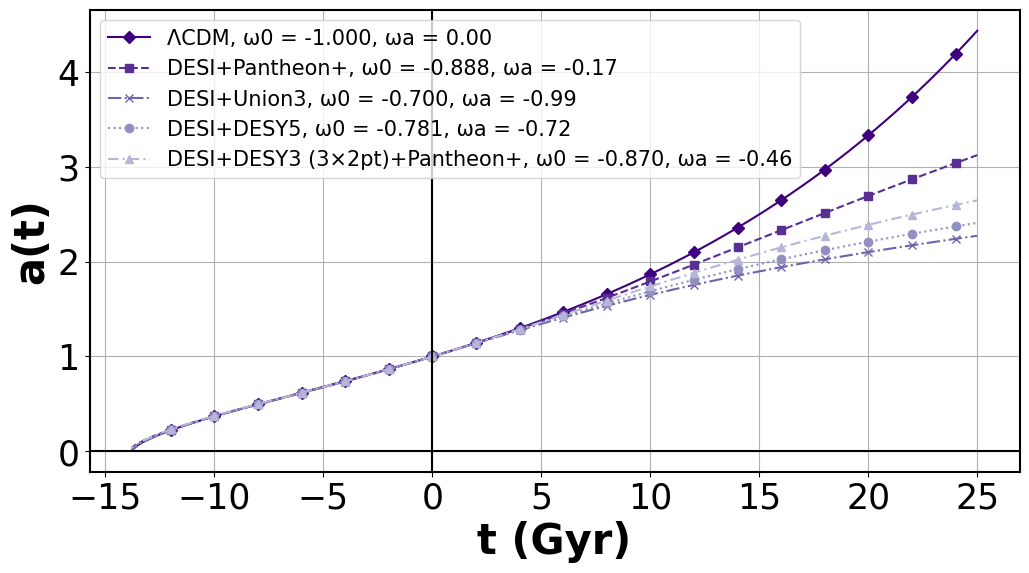

In [4]:
#.....................................................
# Resolución NUMÉRICA ω0ωaCDM - USANDO LISTA DE DATOS
#.....................................................

#---------------------------
# Datos del eje x - temporal 
#---------------------------

t = 0.0  # hoy
dt = 0.01  # 0.01 Gyr = 10 Myr
tF_max = 25.0  # 25 Gyr en el futuro
tB_min = -13.8  # hasta casi el Big Bang
N_F = int((tF_max - t) / dt)
#print("N_F:",N_F)
N_B = int((t - tB_min) / dt)
#print("N_B:",N_B)
#print("Numero de puntos usado:", N_F+N_B)

tF = np.arange(0.0, tF_max, dt)
tB = np.arange(0.0, tB_min, -dt)

#------------
# Constantes 
#------------

# Usamos pues H_0 del CMB, en Gyr:
H_0 = 67.4 / 3.086e+19 # Unidades: s^-1
#print("H_0 en s^-1 =",H_0)
H_0 *= 3600 * 24 * 365 * 10**(9) # Unidades: Gyr^-1
#print("H_0 en Gy^-1 =",H_0)

#---------
# FUNCIÓN: a_punto = H_0 * sqrtΩ_0[0] * a**(-3/2 * (1+ω0 + ωa * (1-a)))
# ω0ωa: ω(a) = ω0 + ωa * (1-a)
# Datos tomados de https://arxiv.org/pdf/2503.14738 pg 20, DESI+Pantheon+: ω0 = -0.888 ωa= -0.17
#---------

#----------------------
# DATOS EXPERIMENTALES 
#----------------------
Datos = ["ΛCDM","DESI+Pantheon+","DESI+Union3","DESI+DESY5","DESI+DESY3 (3×2pt)+Pantheon+"] # nombre de los datos (de dónde han salido)
nDatos = 5 # número de nombres en la lista Datos
colorinchis = ["purple","orange","blue","green","yellow"]
colorinchis = plt.cm.Purples(np.linspace(1, 0.4, 5))
linestyles = ['-', '--', '-.', ':', (0, (5, 2, 1, 2))]
markers = ['D', 's', 'x', 'o', '^']
Ω_0m = [0.3153,0.298,0.328,0.319,0.314]
ω0 = [-1,-0.888,-0.700,-0.781,-0.870]
ωa= [-0,-0.17,-0.99,-0.72,-0.46]

#----------------------
# Resolución NUMÉRICA
#----------------------

# Tamaño --------------------------------
plt.figure(figsize = (12,6))


# FORWARDS -----------
for j in range(nDatos):
    a_numF = np.zeros(N_F)
    a_numF[0] = 1.0   # empezamos en 1
    #a_numF[0] = 1e-6   # empezamos cerca de cero, no en 1    
    for i in range(N_F-1):        
        aF = a_numF[i]
        k1 = H_0 * math.sqrt(Ω_0m[j] / aF + (1-Ω_0m[j]) *  aF**(-1 - 3 * (ω0[j] + ωa[j] * (1-aF))))
        k2 = H_0 * math.sqrt(Ω_0m[j] / (aF + 0.5 * dt * k1) + (1-Ω_0m[j]) *  (aF + 0.5 * dt * k1)**(-1 - 3 * (ω0[j] + ωa[j] * (1-(aF + 0.5 * dt * k1)))))
        k3 = H_0 * math.sqrt(Ω_0m[j] / (aF + 0.5 * dt * k2) + (1-Ω_0m[j]) *  (aF + 0.5 * dt * k2)**(-1 - 3 * (ω0[j] + ωa[j] * (1-(aF + 0.5 * dt * k2)))))
        k4 = H_0 * math.sqrt(Ω_0m[j] / (aF + dt * k3) + (1-Ω_0m[j]) *  (aF + dt * k3)**(-1 - 3 * (ω0[j] + ωa[j] * (1-(aF + dt * k3)))))
        a_numF[i+1] = aF + dt * (k1 + 2*k2 + 2*k3 + k4)/6
    plt.plot(tF, a_numF, label= f"{Datos[j]}, ω0 = {ω0[j]:.3f}, ωa = {ωa[j]:.2f}", color = colorinchis[j], marker=markers[j], markevery=200, linestyle=linestyles[j]) 
            
# BACKWARDS---------
dt=-dt
for j in range(nDatos):
    a_numB = np.zeros(N_B)
    a_numB[0] = 1.0   # empezamos en 1
    #a_numB[0] = 1e-6   # empezamos cerca de cero, no en 1
    for i in range(N_B-1):
        aB = a_numB[i]
        k1 = H_0 * math.sqrt(Ω_0m[j] / aB + (1-Ω_0m[j]) *  aB**(-1 - 3 * (ω0[j] + ωa[j] * (1-aB))))
        k2 = H_0 * math.sqrt(Ω_0m[j] / (aB + 0.5 * dt * k1) + (1-Ω_0m[j]) *  (aB + 0.5 * dt * k1)**(-1 - 3 * (ω0[j] + ωa[j] * (1-(aB + 0.5 * dt * k1)))))
        k3 = H_0 * math.sqrt(Ω_0m[j] / (aB + 0.5 * dt * k2) + (1-Ω_0m[j]) *  (aB + 0.5 * dt * k2)**(-1 - 3 * (ω0[j] + ωa[j] * (1-(aB + 0.5 * dt * k2)))))
        k4 = H_0 * math.sqrt(Ω_0m[j] / (aB + dt * k3) + (1-Ω_0m[j]) *  (aB + dt * k3)**(-1 - 3 * (ω0[j] + ωa[j] * (1-(aB + dt * k3)))))
        a_numB[i+1] = aB + dt * (k1 + 2*k2 + 2*k3 + k4)/6
    plt.plot(tB, a_numB, color = colorinchis[j], marker=markers[j], markevery=200, linestyle=linestyles[j]) 
    #plt.plot(tB, a_numB, label= f"{Datos[j]} RK4 Backwards", color = colorinchis[j]) 
        
    
#----------------------------------------
                # PLOT
#----------------------------------------

# Título y tamaño de gráfica ------------
#plt.title('Evolución del factor de escala temporal ω0ωaCDM para múltiples datos', 
#          fontsize = 20, fontweight = 'bold', color = 'black')

# Títulos de ejes------------------------
plt.xlabel('t (Gyr)', fontsize = 30, fontweight = 'bold', color = 'black')
plt.ylabel('a(t)', fontsize = 30, fontweight = 'bold', color = 'black')

# Etiquetas de los ejes -----------------
    # Tamaño
plt.xticks(fontsize = 25)
plt.yticks(fontsize = 25)

# Trazar los ejes x=0 e y=0 en negrita --
ax = plt.gca()
ax.axhline(0, color = 'black', linewidth = 1.5)
ax.axvline(0, color = 'black', linewidth = 1.5)
for spine in ax.spines.values():
    spine.set_linewidth(1.5)
#ax.set_xlim(-15,15)
#ax.set_ylim(-2,5)

# Leyenda--------------------------------
plt.legend(fontsize = 15)
#plt.legend(fontsize = 15, bbox_to_anchor = (1.05,1), loc = 'upper left')

# Guardar figura
plt.grid(True)
plt.savefig("Fig4_a(t)_w0wa.png")

# Mostrar gráfico -----------------------
plt.show()

## 3. Χ = Χ(z)

### Resoluciones numéricas vs Astropy: Χ = Χ(z), dL(z), dA(z) para Universo plano (Sk(Χ)=Χ)

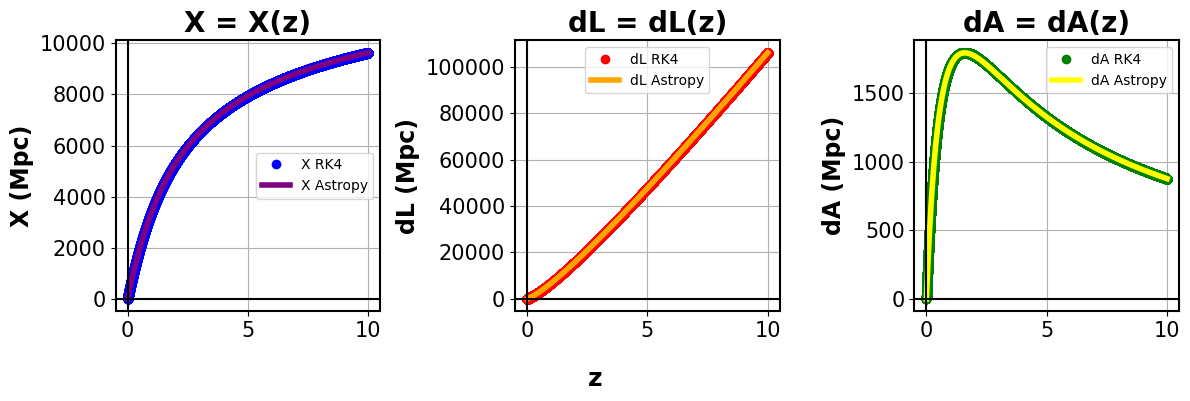

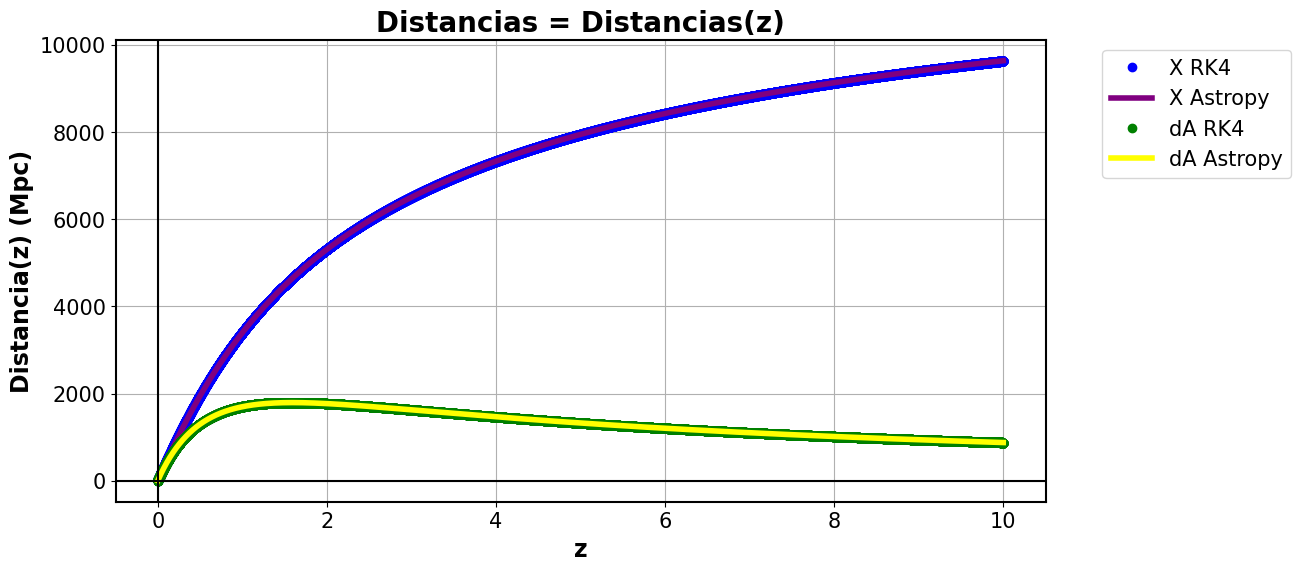

In [5]:
#.........................................................................................
# Resoluciones numéricas vs Astropy: Χ = Χ(z), dL(z), dA(z) para Universo plano (Sk(Χ)=Χ)
#.........................................................................................

#----------------------------
# Datos del eje x - REDSHIFT 
#----------------------------

z0 = 0.0  # hoy
dz = 0.0001  # aumentada resolución respecto a la dt usada con anterioridad
z_CMB = 1000
z_max = 10 # usamos: dz=0.0001 y z_max=10, pero se puede usar: dz=0.001 y z_max=z_CMB=1000 
z = np.arange(z0, z_max, dz)
N = int((z_max - z0) / dz)
#print("array creado para z:",z,"\n")
#print("N:",N,"\n")

#------------
# Constantes 
#------------

# Usamos pues H_0 del CMB, en Gyr:
H_0 = 67.4 / 3.086e+19 # Unidades: s^-1
#print("H_0 en s^-1 =",H_0)
H_0 *= 3600 * 24 * 365 * 10**(9) # Unidades: Gyr^-1
#print("H_0 en Gy^-1 =",H_0)
H_0_ksM = 67.4 # Unidades: km/s/Mpc --------------------------------> ¡OJO! AQUÍ SÍ QUE NECESITO ESTAS UNIDADES

c = const.c / 1000 # Unidades: km/s

# Datos Tabla 2.1 pg 58 Baumann:
names = ["Matter", "Radiation", "Dark Energy"]
colors = ["red","green","blue"]
Ω_0 = [0.3153, 9.02e-5, 0.6847]
#sqrtΩ_0 = [math.sqrt(0.3153), math.sqrt(9.02e-5), math.sqrt(0.6847)]
ω = np.array([0,1/3,-1])

#---------
# FUNCIÓN: Χ_punto = c / H_0_ksM / math.sqrt(Ω_matter * (1+z)**3 + Ω_Λ)
#---------

#---------------------
# Resolución ASTROPY
#---------------------   

Χ_Astropy = Planck18.comoving_distance(z)               # Cálculo distancia comóvil (en Mpc)
dL_Astropy = Planck18.luminosity_distance(z)            # Cálculo distancia de luminosidad (en Mpc)
dA_Astropy = Planck18.angular_diameter_distance(z)      # Cálculo distancia angular (en Mpc)

#---------------------
# Resolución NUMÉRICA
#---------------------    
    
# BACKWARDS---------
Χ_num = np.zeros(N)
#Χ_num[0] = 1.0   # empezamos en 1
Χ_num[0] = 1e-6   # empezamos cerca de cero, no en 1
dL_num = np.zeros(N) # DISTANCIA DE LUMINOSIDAD
dA_num = np.zeros(N) # DISTANCIA DEL DIÁMETRO ANGULAR

for i in range(N-1):
    Χ = Χ_num[i]
    k1 = c / H_0_ksM / math.sqrt(Ω_0[0] * (1+z[i])**3 + Ω_0[2])
    k2 = c / H_0_ksM / math.sqrt(Ω_0[0] * (1+(z[i] + 1/2 * dz))**3 + Ω_0[2])
    k4 = c / H_0_ksM / math.sqrt(Ω_0[0] * (1+(z[i] + dz))**3 + Ω_0[2])
    #if z[i]==0.5: print(f'i ={i}', "\t"f'Χ ={Χ:.2e}',"\t"f'z[i] ={z[i]:.2e}')    
    #if z[i]==0.5: print(f'i ={i}', "\t"f'Χ ={Χ:.2e}',"\t"f'z[i] ={z[i]:.1}')
    Χ_num[i+1] = Χ + dz * (k1 + 4*k2 + k4)/6

for i in range(N):
    dL_num[i] = Χ_num[i] * (1+z[i])
    dA_num[i] = Χ_num[i] / (1+z[i]) 


#----------------------------------------
                # PLOT
#----------------------------------------

# GRÁFICAS PARALELAS Y SEPARADAS -------------------------------------------------------------------------------

fig, axs = plt.subplots(1, 3, figsize=(12, 4))
fig.supxlabel('z', fontsize=18, fontweight="bold")

# ---- Gráfica Χ = Χ(z) ----
axs[0].set_title('Χ = Χ(z)', fontsize = 20, fontweight = 'bold', color = 'black')
axs[0].set_ylabel('Χ (Mpc)', fontsize=17, fontweight='bold')
#axs[0].set_xlabel('z', fontsize=17, fontweight='bold')

axs[0].plot(z, Χ_num, label="Χ RK4", color='blue', linestyle='None',  marker='o')
axs[0].plot(z, Χ_Astropy.value, label="Χ Astropy", color='purple', linewidth=4)
axs[0].legend()
axs[0].grid(True)

# ---- Gráfica dL = dL(z) ----
axs[1].set_title('dL = dL(z)', fontsize = 20, fontweight = 'bold', color = 'black')
axs[1].set_ylabel('dL (Mpc)', fontsize=17, fontweight='bold') #----------------------------> ¡OJO UNIDADES Gpc PARA ESTA GRÁFICA SEPARADA! (en la grande no he mezclado unidades)
#axs[1].set_xlabel('z', fontsize=17, fontweight='bold')

axs[1].plot(z, dL_num, label="dL RK4", color='red', linestyle='None', marker='o')
axs[1].plot(z, dL_Astropy.value, label="dL Astropy", color='orange', linewidth=4)
axs[1].legend()
axs[1].grid(True)

# ---- Gráfica dA = dA(z) ----
axs[2].set_title('dA = dA(z)', fontsize = 20, fontweight = 'bold', color = 'black')
axs[2].set_ylabel('dA (Mpc)', fontsize=17, fontweight='bold')
#axs[2].set_xlabel('z', fontsize=17, fontweight='bold')

axs[2].plot(z, dA_num, label="dA RK4", color='green', linestyle='None', marker='o')
axs[2].plot(z, dA_Astropy.value, label="dA Astropy", color='yellow', linewidth=4)
axs[2].legend()
axs[2].grid(True)

#axs[0].set_xlim(0,2)
#axs[1].set_xlim(0,2)
#axs[1].set_ylim(-5e7,1e7) 

# ---- Ajustes COMUNES a ambos subplots ----
for ax in axs:

    # Etiquetas de los ticks
    ax.tick_params(axis='both', labelsize=15)

    # Ejes x=0 e y=0 en negrita
    ax.axhline(0, color='black', linewidth=1.5)
    ax.axvline(0, color='black', linewidth=1.5)

    # Ejes (spines) en negrita
    for spine in ax.spines.values():
        spine.set_linewidth(1.5)

plt.tight_layout()
plt.show()


# GRÁFICA INICIAL CON TODO JUNTO -------------------------------------------------------------------------------

# Tamaño --------------------------------
plt.figure(figsize = (12,6))

# Ploteo --------------------------------
plt.plot(z, Χ_num, label = "Χ RK4", color='blue', linestyle='None', marker='o')
plt.plot(z, Χ_Astropy.value, label="Χ Astropy", color='purple', linewidth=4)
#plt.plot(z, dL_num, label = "dL RK4 Backwards", color='red', linestyle='None', marker='o')
#plt.plot(z, dL_Astropy.value, label="dL Astropy", color='orange', linewidth=4)
plt.plot(z, dA_num, label = "dA RK4", color='green', linestyle='None', marker='o')
plt.plot(z, dA_Astropy.value, label="dA Astropy", color='yellow', linewidth=4)

# Título y tamaño de gráfica ------------
plt.title('Distancias = Distancias(z)', fontsize = 20, fontweight = 'bold', color = 'black')

# Títulos de ejes------------------------
plt.xlabel('z', fontsize = 17, fontweight = 'bold', color = 'black')
plt.ylabel('Distancia(z) (Mpc)', fontsize = 17, fontweight = 'bold', color = 'black')

# Etiquetas de los ejes -----------------
    # Tamaño
plt.xticks(fontsize = 15)
plt.yticks(fontsize = 15)

# Trazar los ejes x=0 e y=0 en negrita --
ax = plt.gca()
ax.axhline(0, color = 'black', linewidth = 1.5)
ax.axvline(0, color = 'black', linewidth = 1.5)
for spine in ax.spines.values():
    spine.set_linewidth(1.5)
#ax.set_xlim(-15,15)
#ax.set_ylim(-2,5)

# Leyenda--------------------------------
plt.legend(fontsize = 15, bbox_to_anchor = (1.05,1), loc = 'upper left')

# Mostrar gráfico -----------------------
plt.grid(True)
plt.show()

Link información sobre Astropy:
https://docs.astropy.org/en/stable/cosmology/index.html#getting-started

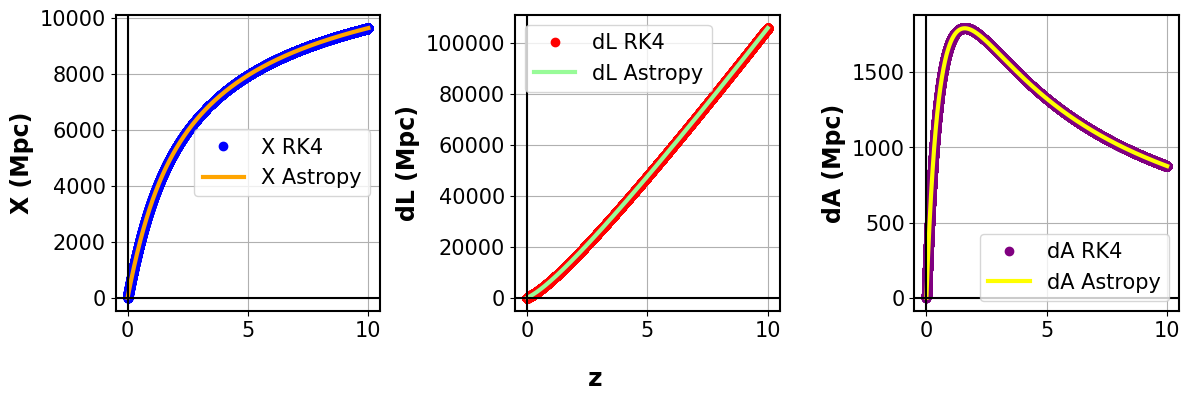

In [6]:
#----------------------------------------
                # PLOT
#----------------------------------------

# GRÁFICAS PARALELAS Y SEPARADAS -------------------------------------------------------------------------------

fig, axs = plt.subplots(1, 3, figsize=(12, 4))
fig.supxlabel('z', fontsize=18, fontweight="bold")

# ---- Gráfica Χ = Χ(z) ----
#axs[0].set_title('Χ = Χ(z)', fontsize = 20, fontweight = 'bold', color = 'black')
axs[0].set_ylabel('Χ (Mpc)', fontsize=17, fontweight='bold')
#axs[0].set_xlabel('z', fontsize=17, fontweight='bold')

axs[0].plot(z, Χ_num, label="Χ RK4", color='blue', linestyle='None',  marker='o')
axs[0].plot(z, Χ_Astropy.value, label="Χ Astropy", color='orange', linewidth=3.0)
axs[0].legend(fontsize = 15)
axs[0].grid(True)

# ---- Gráfica dL = dL(z) ----
#axs[1].set_title('dL = dL(z)', fontsize = 20, fontweight = 'bold', color = 'black')
axs[1].set_ylabel('dL (Mpc)', fontsize=17, fontweight='bold') 
#axs[1].set_xlabel('z', fontsize=17, fontweight='bold')

axs[1].plot(z, dL_num, label="dL RK4", color='red', linestyle='None', marker='o')
axs[1].plot(z, dL_Astropy.value, label="dL Astropy", color='palegreen', linewidth=3.0)
axs[1].legend(fontsize = 15)
axs[1].grid(True)

# ---- Gráfica dA = dA(z) ----
#axs[2].set_title('dA = dA(z)', fontsize = 20, fontweight = 'bold', color = 'black')
axs[2].set_ylabel('dA (Mpc)', fontsize=17, fontweight='bold')
#axs[2].set_xlabel('z', fontsize=17, fontweight='bold')

axs[2].plot(z, dA_num, label="dA RK4", color='purple', linestyle='None', marker='o')
axs[2].plot(z, dA_Astropy.value, label="dA Astropy", color='yellow', linewidth=3.0)
axs[2].legend(fontsize = 15)
axs[2].grid(True)

#axs[0].set_xlim(0,2)
#axs[1].set_xlim(0,2)
#axs[1].set_ylim(-5e7,1e7) 

# ---- Ajustes COMUNES a ambos subplots ----
for ax in axs:

    # Etiquetas de los ticks
    ax.tick_params(axis='both', labelsize=15)

    # Ejes x=0 e y=0 en negrita
    ax.axhline(0, color='black', linewidth=1.5)
    ax.axvline(0, color='black', linewidth=1.5)

    # Ejes (spines) en negrita
    for spine in ax.spines.values():
        spine.set_linewidth(1.5)

# Guardar figura
plt.savefig("Fig5_distanciasX_L_A(z).png")

plt.tight_layout()
plt.show()
